# Week 1 — E-Commerce Customer Behavior & Retention Analysis (Olist)

**Tujuan notebook:** memahami struktur data, memeriksa kualitas, membersihkan dan mengintegrasikan tabel, lalu menginvestigasi konsistensi nilai pembayaran.

**Alur analisis:** Data Understanding → Data Quality → Cleaning & Validation → Integration → Transaction Aggregation → Payment Anomaly Investigation.





In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
data1 = "/content/drive/MyDrive/Portofolio/Project E-Commerce Customer Behavior & Retention Analysis/Dataset Project E-Commerce Customer Behavior & Retention Analysis/olist_orders_dataset.csv"

df1 = pd.read_csv(data1)
df1.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
df1.shape

(99441, 8)

In [ ]:
df1.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='object')

In [ ]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [ ]:
df1.describe(include="all")

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-08-02 12:06:07,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [ ]:
df1.isnull().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [ ]:
df1.duplicated().sum()

np.int64(0)

In [ ]:
df1.dtypes

,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,object
order_approved_at,object
order_delivered_carrier_date,object
order_delivered_customer_date,object
order_estimated_delivery_date,object


In [ ]:
# Memperbaiki sintaks akses kolom dengan menghapus titik sebelum kurung siku
df1["order_status"].unique()

array(['delivered', 'invoiced', 'shipped', 'processing', 'unavailable',
       'canceled', 'created', 'approved'], dtype=object)

In [ ]:
# Menghitung jumlah kemunculan dari setiap nilai unik pada kolom 'order_status'
hitung_status = df1["order_status"].value_counts()
print(hitung_status)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


### 1. Data Understanding

**Tujuan:** Memahami struktur dataset Brazilian E-Commerce Public Dataset by Olist sebelum melakukan pembersihan dan penggabungan data.

Dataset terdiri dari 9 file CSV yang mencakup informasi pesanan, pelanggan, produk, pembayaran, penjual, ulasan, lokasi geografis, item pesanan, dan terjemahan kategori produk.

**Temuan awal:**
- `orders` memiliki 99.441 baris, dengan satu baris mewakili satu pesanan.
- `customers` memiliki 99.441 baris.
- `order_items` memiliki 112.650 baris karena satu pesanan dapat memiliki lebih dari satu item.
- `payments` memiliki 103.886 baris karena satu pesanan dapat memiliki lebih dari satu catatan pembayaran.
- `products` memiliki 32.951 baris.

**Insight:**

Setiap tabel memiliki tingkat detail (*granularity*) yang berbeda. Oleh karena itu, hubungan antartabel harus dipahami sebelum melakukan JOIN agar tidak terjadi penggandaan data dan kesalahan perhitungan metrik bisnis.

**Keputusan analisis:** Menggunakan `order_id` sebagai kunci utama untuk analisis tingkat pesanan dan `customer_unique_id` untuk analisis pelanggan berulang.

In [ ]:
# 1. Buat salinan dari kolom order_purchase_timestamp agar tidak mengubah DataFrame asli
purchase_date_copy = df1['order_purchase_timestamp'].copy()

# 2. Hitung jumlah data kosong sebelum konversi
missing_before = purchase_date_copy.isna().sum()

# 3. Lakukan konversi dengan errors='coerce'
purchase_date_converted = pd.to_datetime(purchase_date_copy, errors='coerce')

# 4. Hitung jumlah data kosong setelah konversi
missing_after = purchase_date_converted.isna().sum()

# 5. Hitung jumlah data yang formatnya tidak sesuai (gagal dikonversi)
invalid_dates = missing_after - missing_before

print(f"Jumlah data kosong asli sebelum konversi: {missing_before}")
print(f"Jumlah data kosong/gagal setelah konversi: {missing_after}")
print(f"Jumlah data dengan format tidak sesuai/error: {invalid_dates}")

# Menampilkan beberapa sampel data yang berhasil dikonversi
print("\nSampel hasil konversi:")
print(purchase_date_converted.head())

Jumlah data kosong asli sebelum konversi: 0
Jumlah data kosong/gagal setelah konversi: 0
Jumlah data dengan format tidak sesuai/error: 0

Sampel hasil konversi:
0   2017-10-02 10:56:33
1   2018-07-24 20:41:37
2   2018-08-08 08:38:49
3   2017-11-18 19:28:06
4   2018-02-13 21:18:39
Name: order_purchase_timestamp, dtype: datetime64[ns]


In [ ]:
df1.groupby("order_status")[
    "order_delivered_customer_date"
].apply(lambda x: x.isnull().sum())

,order_delivered_customer_date
order_status,
approved,2
canceled,619
created,5
delivered,8
invoiced,314
processing,301
shipped,1107
unavailable,609


### 2. Data Quality Assessment

**Tujuan:** Mengidentifikasi masalah kualitas data sebelum melakukan transformasi.

**Temuan:**
- Terdapat nilai kosong pada beberapa kolom tanggal pengiriman.
- Sebanyak 1.603 baris item produk memiliki kategori produk yang kosong setelah penggabungan dengan tabel produk.
- Terdapat perbedaan jumlah baris dan jumlah pesanan unik pada tabel item serta pembayaran.

**Insight:**

Nilai kosong tidak selalu berarti data salah. Misalnya, tanggal pengiriman yang kosong dapat berkaitan dengan status pesanan yang belum selesai atau dibatalkan.

Demikian juga, beberapa baris dengan `order_id` yang sama pada tabel `order_items` dan `payments` tidak otomatis merupakan duplikasi, karena masing-masing baris dapat mewakili item atau pembayaran yang berbeda.

**Keputusan analisis:** Tidak menghapus data secara otomatis. Setiap masalah kualitas data diperiksa berdasarkan konteks bisnis dan struktur tabel.

In [ ]:
dfclean = df1.copy()
dfclean

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00


In [ ]:
dfclean["order_purchase_timestamp"] = pd.to_datetime(
    dfclean["order_purchase_timestamp"],
    errors="coerce"
)

In [ ]:
dfclean.dtypes

,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,datetime64[ns]
order_approved_at,object
order_delivered_carrier_date,object
order_delivered_customer_date,object
order_estimated_delivery_date,object


In [ ]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

# Menggunakan loop untuk mengonversi setiap kolom ke tipe datetime
for col in date_columns:
    dfclean[col] = pd.to_datetime(dfclean[col], errors="coerce")

# Menampilkan tipe data terbaru untuk memastikan perubahan
dfclean[date_columns].dtypes

,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


In [ ]:
# Menghitung berapa banyak transaksi yang tanggal approval-nya sebelum tanggal pembelian
# (Ini adalah kondisi tidak logis/error)
undated_orders = (dfclean["order_approved_at"] < dfclean["order_purchase_timestamp"]).sum()

print(f"Jumlah transaksi dengan order_approved_at sebelum order_purchase_timestamp: {undated_orders}")

Jumlah transaksi dengan order_approved_at sebelum order_purchase_timestamp: 0


In [ ]:
# Memfilter data dengan status 'delivered' lalu menghitung jumlah nilai kosong pada tanggal pengiriman
delivered_missing_date = dfclean[dfclean["order_status"] == "delivered"]["order_delivered_customer_date"].isnull().sum()

print(f"Jumlah pesanan 'delivered' yang tidak memiliki tanggal pengiriman: {delivered_missing_date}")

Jumlah pesanan 'delivered' yang tidak memiliki tanggal pengiriman: 8


In [ ]:
#day4
# Menghitung berapa banyak transaksi yang tanggal pengiriman ke customer-nya
# lebih awal (sebelum) tanggal penyerahan ke kurir
invalid_delivery_dates = (dfclean["order_delivered_customer_date"] < dfclean["order_delivered_carrier_date"]).sum()

print(f"Jumlah transaksi dengan order_delivered_customer_date sebelum order_delivered_carrier_date: {invalid_delivery_dates}")

Jumlah transaksi dengan order_delivered_customer_date sebelum order_delivered_carrier_date: 23


In [ ]:
# Memastikan kolom delivery_days sudah dibuat di dfclean
dfclean["delivery_days"] = (
    dfclean["order_delivered_customer_date"] - dfclean["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Memfilter pesanan yang berstatus 'delivered' dan memiliki data tanggal yang lengkap (tidak null)
delivered_orders = dfclean[
    (dfclean["order_status"] == "delivered") &
    (dfclean["order_purchase_timestamp"].notnull()) &
    (dfclean["order_delivered_customer_date"].notnull())
]

# Menghitung rata-rata delivery_days
avg_delivery_days = delivered_orders["delivery_days"].mean()

print(f"Rata-rata delivery_days untuk pesanan 'delivered' dengan data lengkap: {avg_delivery_days:.2f} hari")

Rata-rata delivery_days untuk pesanan 'delivered' dengan data lengkap: 12.56 hari


In [ ]:
# 1. Mencari durasi pengiriman paling lama
max_delivery = dfclean["delivery_days"].max()
print(f"Durasi pengiriman paling lama: {max_delivery:.2f} hari")

# 2. Memeriksa apakah terdapat durasi pengiriman negatif
negative_delivery_count = (dfclean["delivery_days"] < 0).sum()
print(f"Jumlah transaksi dengan durasi pengiriman negatif: {negative_delivery_count}")

Durasi pengiriman paling lama: 209.63 hari
Jumlah transaksi dengan durasi pengiriman negatif: 0


In [ ]:
orders_clean = dfclean.copy()

### 3. Data Cleaning — Date Transformation

**Tujuan:** Mengubah kolom tanggal menjadi format datetime agar dapat digunakan dalam analisis waktu dan durasi pengiriman.

**Proses:**
- Mengonversi lima kolom timestamp pada tabel pesanan menjadi tipe datetime.
- Membuat kolom `delivery_days` untuk menghitung durasi dari pembelian hingga pesanan diterima pelanggan.
- Mempertahankan nilai tanggal kosong untuk diperiksa berdasarkan status pesanan.

**Hasil:**
- Jumlah pesanan tetap 99.441.
- Rata-rata durasi pengiriman pesanan yang memiliki data tanggal lengkap adalah sekitar 12,56 hari.
- Durasi pengiriman terpanjang sekitar 209,63 hari.

**Insight:**

Variasi durasi pengiriman menunjukkan adanya perbedaan pengalaman pelanggan dalam menerima pesanan. Pesanan dengan durasi sangat panjang dapat menjadi objek investigasi lebih lanjut untuk memahami keterlambatan pengiriman.

Durasi pengiriman yang panjang belum otomatis menunjukkan pelanggaran estimasi pengiriman, karena perlu dibandingkan dengan tanggal estimasi yang dijanjikan.

In [ ]:
data2 = "/content/drive/MyDrive/Portofolio/Project E-Commerce Customer Behavior & Retention Analysis/Dataset Project E-Commerce Customer Behavior & Retention Analysis/olist_customers_dataset.csv"
customers = pd.read_csv(data2)
customers

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
...,...,...,...,...,...
99436,17ddf5dd5d51696bb3d7c6291687be6f,1a29b476fee25c95fbafc67c5ac95cf8,3937,sao paulo,SP
99437,e7b71a9017aa05c9a7fd292d714858e8,d52a67c98be1cf6a5c84435bd38d095d,6764,taboao da serra,SP
99438,5e28dfe12db7fb50a4b2f691faecea5e,e9f50caf99f032f0bf3c55141f019d99,60115,fortaleza,CE
99439,56b18e2166679b8a959d72dd06da27f9,73c2643a0a458b49f58cea58833b192e,92120,canoas,RS


In [ ]:
# Menghitung berapa banyak customer_id di orders_clean yang ada di dataset customers
matched_customers = orders_clean["customer_id"].isin(customers["customer_id"]).sum()
print(f"Jumlah customer_id yang cocok: {matched_customers}")

Jumlah customer_id yang cocok: 99441


In [ ]:
# Menghitung jumlah customer_id di orders_clean yang TIDAK cocok dengan dataset customers
notmatched_customers = (~orders_clean["customer_id"].isin(customers["customer_id"])).sum()
print(f"Jumlah customer_id yang tidak cocok: {notmatched_customers}")

Jumlah customer_id yang tidak cocok: 0


### 4. Data Validation

**Tujuan:** Memastikan data memiliki hubungan dan urutan waktu yang logis.

**Temuan:**
- Terdapat 23 pesanan dengan tanggal diterima pelanggan lebih awal daripada tanggal penyerahan ke kurir.
- Terdapat 8 pesanan berstatus `delivered` tetapi tidak memiliki tanggal penerimaan pelanggan.
- Tidak ditemukan durasi negatif antara tanggal pembelian dan tanggal penerimaan pelanggan pada data yang dapat dihitung.
- Seluruh `customer_id` pada tabel pesanan berhasil dicocokkan dengan tabel pelanggan.

**Insight:**

Secara umum, relasi antara pesanan dan pelanggan memiliki integritas referensial yang baik. Namun, ditemukan sejumlah ketidakkonsistenan tanggal yang memerlukan investigasi.

**Keputusan analisis:** Menandai temuan tersebut sebagai potensi masalah kualitas data, bukan langsung menghapus atau memperbaiki tanggal tanpa bukti pendukung.

In [ ]:
#Day5
data3 = "/content/drive/MyDrive/Portofolio/Project E-Commerce Customer Behavior & Retention Analysis/Dataset Project E-Commerce Customer Behavior & Retention Analysis/olist_order_items_dataset.csv"
order_items = pd.read_csv(data3)
order_items

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14
...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72


In [ ]:
data4 = "/content/drive/MyDrive/Portofolio/Project E-Commerce Customer Behavior & Retention Analysis/Dataset Project E-Commerce Customer Behavior & Retention Analysis/olist_products_dataset.csv"
products = pd.read_csv(data4)
products

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0
...,...,...,...,...,...,...,...,...,...
32946,a0b7d5a992ccda646f2d34e418fff5a0,moveis_decoracao,45.0,67.0,2.0,12300.0,40.0,40.0,40.0
32947,bf4538d88321d0fd4412a93c974510e6,construcao_ferramentas_iluminacao,41.0,971.0,1.0,1700.0,16.0,19.0,16.0
32948,9a7c6041fa9592d9d9ef6cfe62a71f8c,cama_mesa_banho,50.0,799.0,1.0,1400.0,27.0,7.0,27.0
32949,83808703fc0706a22e264b9d75f04a2e,informatica_acessorios,60.0,156.0,2.0,700.0,31.0,13.0,20.0


In [ ]:
print("Orders:", orders_clean.shape)
print("Customers:", customers.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)

Orders: (99441, 9)
Customers: (99441, 5)
Order Items: (112650, 7)
Products: (32951, 9)


In [ ]:
orders_customers = orders_clean.merge(
    customers,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

orders_customers.shape

(99441, 13)

In [ ]:
orders_items = orders_clean.merge(
    order_items,
    on="order_id",
    how="left",
    validate="one_to_many"
)

orders_items.shape

(113425, 15)

In [ ]:
orders_items["order_id"].nunique()

99441

In [ ]:
order_items[
    order_items.duplicated(
        subset=["order_id"],
        keep=False
    )
].sort_values("order_id")

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
13,0008288aa423d2a3f00fcb17cd7d8719,1,368c6c730842d78016ad823897a372db,1f50f920176fa81dab994f9023523100,2018-02-21 02:55:52,49.90,13.37
14,0008288aa423d2a3f00fcb17cd7d8719,2,368c6c730842d78016ad823897a372db,1f50f920176fa81dab994f9023523100,2018-02-21 02:55:52,49.90,13.37
32,00143d0f86d6fbd9f9b38ab440ac16f5,1,e95ee6822b66ac6058e2e4aff656071a,a17f621c590ea0fab3d5d883e1630ec6,2017-10-20 16:07:52,21.33,15.10
33,00143d0f86d6fbd9f9b38ab440ac16f5,2,e95ee6822b66ac6058e2e4aff656071a,a17f621c590ea0fab3d5d883e1630ec6,2017-10-20 16:07:52,21.33,15.10
34,00143d0f86d6fbd9f9b38ab440ac16f5,3,e95ee6822b66ac6058e2e4aff656071a,a17f621c590ea0fab3d5d883e1630ec6,2017-10-20 16:07:52,21.33,15.10
...,...,...,...,...,...,...,...
112634,fff8287bbae429a99bb7e8c21d151c41,1,bee2e070c39f3dd2f6883a17a5f0da45,4e922959ae960d389249c378d1c939f5,2018-03-27 12:29:22,180.00,48.14
112641,fffb9224b6fc7c43ebb0904318b10b5f,2,43423cdffde7fda63d0414ed38c11a73,b1fc4f64df5a0e8b6913ab38803c57a9,2017-11-03 02:55:58,55.00,34.19
112642,fffb9224b6fc7c43ebb0904318b10b5f,3,43423cdffde7fda63d0414ed38c11a73,b1fc4f64df5a0e8b6913ab38803c57a9,2017-11-03 02:55:58,55.00,34.19
112640,fffb9224b6fc7c43ebb0904318b10b5f,1,43423cdffde7fda63d0414ed38c11a73,b1fc4f64df5a0e8b6913ab38803c57a9,2017-11-03 02:55:58,55.00,34.19


In [ ]:
#Day6
items_products = order_items.merge(
    products,
    on="product_id",
    how="left",
    validate="many_to_one"
)

print("Sebelum JOIN:", order_items.shape)
print("Sesudah JOIN:", items_products.shape)

Sebelum JOIN: (112650, 7)
Sesudah JOIN: (112650, 15)


In [ ]:
#produk yang tidak memiliki pasanga
items_products["product_category_name"].isna().sum()

np.int64(1603)

In [ ]:
items_products

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41,utilidades_domesticas,43.0,1002.0,3.0,10150.0,89.0,15.0,40.0
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53,informatica_acessorios,31.0,232.0,1.0,8950.0,45.0,26.0,38.0
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95,esporte_lazer,43.0,869.0,1.0,967.0,21.0,24.0,19.0
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72,informatica_acessorios,56.0,1306.0,1.0,100.0,20.0,20.0,20.0


In [ ]:
items_products_check = order_items.merge(
    products,
    on="product_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

In [ ]:
items_products_check["_merge"].value_counts()

,count
_merge,
both,112650
left_only,0
right_only,0


In [ ]:
items_products_check[
    "product_category_name"
].isna()

,product_category_name
0,False
1,False
2,False
3,False
4,False
...,...
112645,False
112646,False
112647,False
112648,False


In [ ]:
# Menyaring produk yang berhasil di-JOIN ('both') tetapi memiliki nama kategori produk kosong (NaN)
missing_category_both = items_products_check[
    items_products_check["product_category_name"].isna() &
    (items_products_check["_merge"] == "both")
]

# Menampilkan jumlah baris dan beberapa sampel data
print(f"Jumlah baris yang sukses JOIN tetapi kategori produknya kosong: {len(missing_category_both)}")
display(missing_category_both)

Jumlah baris yang sukses JOIN tetapi kategori produknya kosong: 1603


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,_merge
123,0046e1d57f4c07c8c92ab26be8c3dfc0,1,ff6caf9340512b8bf6d2a2a6df032cfa,38e6dada03429a47197d5d584d793b41,2017-10-02 15:49:17,7.79,7.78,NaN,NaN,NaN,NaN,200.0,16.0,5.0,12.0,both
125,00482f2670787292280e0a8153d82467,1,a9c404971d1a5b1cbc2e4070e02731fd,702835e4b785b67a084280efca355756,2017-02-17 16:18:07,7.60,10.96,NaN,NaN,NaN,NaN,700.0,35.0,14.0,11.0,both
132,004f5d8f238e8908e6864b874eda3391,1,5a848e4ab52fd5445cdc07aab1c40e48,c826c40d7b19f62a09e2d7c5e7295ee2,2018-03-06 09:29:25,122.99,15.61,NaN,NaN,NaN,NaN,400.0,20.0,12.0,15.0,both
142,0057199db02d1a5ef41bacbf41f8f63b,1,41eee23c25f7a574dfaf8d5c151dbb12,e5a3438891c0bfdb9394643f95273d8e,2018-01-25 09:07:51,20.30,16.79,NaN,NaN,NaN,NaN,200.0,16.0,2.0,11.0,both
171,006cb7cafc99b29548d4f412c7f9f493,1,e10758160da97891c2fdcbc35f0f031d,323ce52b5b81df2cd804b017b7f09aa7,2018-02-22 13:35:28,56.00,14.14,NaN,NaN,NaN,NaN,2200.0,16.0,2.0,11.0,both
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112306,ff24fec69b7f3d30f9dc1ab3aee7c179,1,5a848e4ab52fd5445cdc07aab1c40e48,c826c40d7b19f62a09e2d7c5e7295ee2,2018-02-01 02:40:12,122.99,15.61,NaN,NaN,NaN,NaN,400.0,20.0,12.0,15.0,both
112333,ff3024474be86400847879103757d1fd,1,f9b1795281ce51b1cf39ef6d101ae8ab,3771c85bac139d2344864ede5d9341e3,2017-11-21 03:55:39,39.90,9.94,NaN,NaN,NaN,NaN,400.0,32.0,15.0,15.0,both
112350,ff3a45ee744a7c1f8096d2e72c1a23e4,1,b61d1388a17e3f547d2bc218df02335b,07017df32dc5f2f1d2801e579548d620,2017-05-10 10:15:19,139.00,21.42,NaN,NaN,NaN,NaN,350.0,16.0,6.0,11.0,both
112438,ff7b636282b98e0aa524264b295ed928,1,431df35e52c10451171d8037482eeb43,6cd68b3ed6d59aaa9fece558ad360c0a,2018-02-22 15:35:35,49.90,15.11,NaN,NaN,NaN,NaN,475.0,21.0,15.0,21.0,both


In [ ]:
# copydata
items_products_clean = items_products.copy()

In [ ]:
#melabeli data kosong unknow
items_products_clean["product_category_name"] = (
    items_products_clean["product_category_name"]
    .fillna("Unknown")
)

In [ ]:
items_products_clean[
    "product_category_name"
].isna().sum()

np.int64(0)

In [ ]:
# Menghitung jumlah produk dengan kategori 'Unknown'
(items_products_clean["product_category_name"] == "Unknown").sum()

np.int64(1603)

In [ ]:
# Menghitung jumlah kemunculan setiap kategori termasuk 'Unknown'
category_counts = items_products_clean["product_category_name"].value_counts()

# Menampilkan hasil khusus untuk 'Unknown' dan beberapa sampel kategori teratas
print(f"Jumlah baris dengan kategori 'Unknown': {category_counts.get('Unknown', 0)}\n")
print("Detail value_counts untuk beberapa kategori:")
print(category_counts)

Jumlah baris dengan kategori 'Unknown': 1603

Detail value_counts untuk beberapa kategori:
product_category_name
cama_mesa_banho                  11115
beleza_saude                      9670
esporte_lazer                     8641
moveis_decoracao                  8334
informatica_acessorios            7827
                                 ...  
cds_dvds_musicais                   14
la_cuisine                          14
pc_gamer                             9
fashion_roupa_infanto_juvenil        8
seguros_e_servicos                   2
Name: count, Length: 74, dtype: int64


### 5. Data Integration

**Tujuan:** Menggabungkan informasi dari beberapa tabel untuk mendukung analisis transaksi dan pelanggan.

**Hasil penggabungan:**
- JOIN `orders` dengan `customers` menghasilkan 99.441 baris dan 13 kolom.
- LEFT JOIN `orders` dengan `order_items` menghasilkan 113.425 baris.
- JOIN `order_items` dengan `products` menghasilkan 112.650 baris.
- Sebanyak 1.603 baris item tidak memiliki kategori produk dan diberi label `Unknown`.

**Insight:**

Bertambahnya jumlah baris setelah JOIN pesanan dengan item merupakan konsekuensi hubungan *one-to-many*, bukan otomatis kesalahan data.

Label `Unknown` digunakan agar transaksi dengan kategori yang tidak tersedia tetap dapat dipertahankan dalam analisis.

**Keputusan analisis:** Menyesuaikan metode penggabungan dengan tingkat detail tabel dan menggunakan validasi relasi untuk menghindari kesalahan perhitungan.

Day 7 Revenue Analysis & Double Counting

In [ ]:
order_items["price"].sum()

np.float64(13591643.7)

In [ ]:
order_items["freight_value"].sum()

np.float64(2251909.54)

### Transaction Value Analysis

**Tujuan:** Memahami komponen nilai transaksi pada dataset Olist.

**Hasil:**
- Total nilai produk: R$13.591.643,70.

- Total ongkos kirim: R$2.251.909,54.

**Insight:**

Nilai produk dan ongkos kirim merupakan dua komponen transaksi yang berbeda. Keduanya perlu dipisahkan agar analisis nilai barang tidak tercampur dengan biaya pengiriman.

Total `price` mencerminkan nilai barang yang tercatat pada item pesanan, bukan otomatis pendapatan bersih perusahaan. Analisis pendapatan yang lebih spesifik memerlukan definisi bisnis dan penyaringan status transaksi yang sesuai.

In [ ]:
order_items["order_id"].unique().shape

(98666,)

In [ ]:
total_price_per_order = (
    order_items.groupby("order_id")["price"]
    .sum()
    .reset_index(name="total_price")
)

In [ ]:
print(total_price_per_order)

                               order_id  total_price
0      00010242fe8c5a6d1ba2dd792cb16214        58.90
1      00018f77f2f0320c557190d7a144bdd3       239.90
2      000229ec398224ef6ca0657da4fc703e       199.00
3      00024acbcdf0a6daa1e931b038114c75        12.99
4      00042b26cf59d7ce69dfabb4e55b4fd9       199.90
...                                 ...          ...
98661  fffc94f6ce00a00581880bf54a75a037       299.99
98662  fffcd46ef2263f404302a634eb57f7eb       350.00
98663  fffce4705a9662cd70adb13d4a31832d        99.90
98664  fffe18544ffabc95dfada21779c9644f        55.99
98665  fffe41c64501cc87c801fd61db3f6244        43.00

[98666 rows x 2 columns]


In [ ]:
items_agg = (
    order_items.groupby("order_id")
    .agg(
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum")
    )
    .reset_index()
    )
items_agg

,order_id,total_price,total_freight
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14
...,...,...,...
98661,fffc94f6ce00a00581880bf54a75a037,299.99,43.41
98662,fffcd46ef2263f404302a634eb57f7eb,350.00,36.53
98663,fffce4705a9662cd70adb13d4a31832d,99.90,16.95
98664,fffe18544ffabc95dfada21779c9644f,55.99,8.72


In [ ]:
items_agg.shape

(98666, 3)

In [ ]:
order_items.shape

(112650, 7)

In [ ]:
data5 = "/content/drive/MyDrive/Portofolio/Project E-Commerce Customer Behavior & Retention Analysis/Dataset Project E-Commerce Customer Behavior & Retention Analysis/olist_order_payments_dataset.csv"
payments = pd.read_csv(data5)
payments.shape

(103886, 5)

In [ ]:
payments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [ ]:
payments_agg = (
    payments.groupby("order_id")
    .agg(
        total_payment=("payment_value", "sum")
    )
    .reset_index()
)
payments_agg.head()

,order_id,total_payment
0,00010242fe8c5a6d1ba2dd792cb16214,72.19
1,00018f77f2f0320c557190d7a144bdd3,259.83
2,000229ec398224ef6ca0657da4fc703e,216.87
3,00024acbcdf0a6daa1e931b038114c75,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04


In [ ]:
payments_agg.shape

(99440, 2)

In [ ]:
payments.shape

(103886, 5)

In [ ]:
payments_agg["order_id"].nunique()

99440

In [ ]:
items_agg["order_id"].duplicated().sum()

np.int64(0)

In [ ]:
payments_agg["order_id"].duplicated().sum()

np.int64(0)

In [ ]:
#buat tabel order transaksi
order_transactions = orders_clean.merge(
    items_agg,
    on="order_id",
    how="left",
    validate="one_to_one"
)

In [ ]:
order_transactions = order_transactions.merge(
    payments_agg,
    on="order_id",
    how="left",
    validate="one_to_one"
)

In [ ]:
print(order_transactions.shape)

print(
    order_transactions["order_id"].nunique()
)

print(
    order_transactions["order_id"].duplicated().sum()
)

(99441, 12)
99441
0


In [ ]:
order_transactions[
    ["total_price", "total_freight", "total_payment"]
].isna().sum()

,0
total_price,775
total_freight,775
total_payment,1


### Transaction Aggregation

**Tujuan:** Membentuk dataset transaksi dengan satu baris untuk setiap pesanan.

**Proses:**
- Mengagregasi nilai produk dan ongkos kirim berdasarkan `order_id`.
- Mengagregasi total pembayaran berdasarkan `order_id`.
- Menggabungkan hasil agregasi dengan tabel pesanan menggunakan LEFT JOIN.
- Memvalidasi hubungan menggunakan `validate="one_to_one"`.

**Hasil:**
- `order_transactions` memiliki 99.441 baris dan 99.441 `order_id` unik.
- Tidak ditemukan duplikasi `order_id`.
- Sebanyak 775 pesanan tidak memiliki nilai `total_price` dan `total_freight`.
- Satu pesanan tidak memiliki nilai `total_payment`.

**Insight:**

Agregasi sebelum JOIN sangat penting untuk menghindari *double counting*. Jika tabel item dan pembayaran yang sama-sama memiliki beberapa baris per pesanan digabungkan secara langsung, nilai transaksi dapat terhitung berulang.

**Keputusan analisis:** Menggunakan dataset dengan satu baris per pesanan sebagai dasar perhitungan metrik tingkat transaksi.

In [ ]:
#menambahkan kolom baru
order_transactions["expected_payment"] = (
    order_transactions["total_price"]
    + order_transactions["total_freight"]
)

In [ ]:
order_transactions[
    ["order_id", "total_price",
     "total_freight", "total_payment",
     "expected_payment"]
].head()

,order_id,total_price,total_freight,total_payment,expected_payment
0,e481f51cbdc54678b7cc49136f2d6af7,29.99,8.72,38.71,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,118.70,22.76,141.46,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,159.90,19.22,179.12,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,45.00,27.20,72.20,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,19.90,8.72,28.62,28.62


In [ ]:
order_transactions

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,total_price,total_freight,total_payment,expected_payment
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,29.99,8.72,38.71,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,118.70,22.76,141.46,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,159.90,19.22,179.12,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,45.00,27.20,72.20,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,19.90,8.72,28.62,28.62
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,8.218009,72.00,13.08,85.08,85.08
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,22.193727,174.90,20.10,195.00,195.00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,24.859421,205.99,65.02,271.01,271.01
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,17.086424,359.98,81.18,441.16,441.16


In [ ]:
order_transactions["payment_difference"] = (
    order_transactions["total_payment"]
    - order_transactions["expected_payment"]
)

In [ ]:
(order_transactions["payment_difference"].abs() > 0.01).sum()

np.int64(381)

In [ ]:
order_transactions["payment_difference"].max()

182.80999999999995

In [ ]:
order_transactions["payment_difference"].isnull().sum()

np.int64(776)

In [ ]:
order_transactions["payment_difference"].isna().sum()

np.int64(776)

In [ ]:
(order_transactions["payment_difference"].abs() < 0).sum()

np.int64(0)

In [ ]:
order_transactions

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,total_price,total_freight,total_payment,expected_payment,payment_difference
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,29.99,8.72,38.71,38.71,0.000000e+00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,118.70,22.76,141.46,141.46,0.000000e+00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,159.90,19.22,179.12,179.12,0.000000e+00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,45.00,27.20,72.20,72.20,0.000000e+00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,19.90,8.72,28.62,28.62,3.552714e-15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,8.218009,72.00,13.08,85.08,85.08,0.000000e+00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,22.193727,174.90,20.10,195.00,195.00,0.000000e+00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,24.859421,205.99,65.02,271.01,271.01,0.000000e+00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,17.086424,359.98,81.18,441.16,441.16,0.000000e+00


### Payment Validation

**Tujuan:** Membandingkan total pembayaran yang tercatat dengan jumlah nilai produk dan ongkos kirim.

**Hasil:**
- Terdapat 381 pesanan dengan selisih pembayaran absolut lebih dari R$0,01.

- Selisih absolut terbesar adalah R$182,81.

- Sebanyak 776 pesanan tidak dapat dihitung selisihnya karena terdapat komponen pembayaran atau item yang kosong.

**Insight:**

Sebagian besar pesanan yang dapat dibandingkan memiliki nilai pembayaran yang sesuai dengan komponen produk dan ongkos kirim.

Namun, terdapat 381 pesanan yang perlu ditelusuri lebih lanjut. Selisih ini tidak otomatis menunjukkan kesalahan pembayaran karena mungkin terdapat aturan bisnis atau penyesuaian transaksi yang belum tercakup dalam perhitungan.

**Keputusan analisis:** Mempertahankan transaksi anomali untuk investigasi berdasarkan status pesanan dan metode pembayaran.

In [ ]:
payment_anomalies = order_transactions[
    order_transactions["payment_difference"].abs() > 0.01
].copy()

print(payment_anomalies.shape)

(381, 14)


In [ ]:
payment_anomalies.shape

(381, 14)

In [ ]:
payment_anomalies["order_status"].value_counts()

,count
order_status,
delivered,375
shipped,3
canceled,2
invoiced,1


In [ ]:
payment_anomalies.groupby("order_status").agg(
    avg_difference=("payment_difference", "mean")
)

,avg_difference
order_status,
canceled,16.005000
delivered,7.551733
invoiced,0.010000
shipped,2.300000


In [ ]:
(payment_anomalies["payment_difference"] > 0).sum()

np.int64(291)

In [ ]:
(payment_anomalies["payment_difference"] < 0).sum()

np.int64(90)

In [ ]:
# Memfilter pesanan 'delivered' kemudian menghitung berapa yang selisihnya positif (> 0) dan negatif (< 0)
delivered_anomalies = payment_anomalies[payment_anomalies["order_status"] == "delivered"]

# Mengategorikan selisih pembayaran dan menghitung jumlahnya
delivered_anomalies["payment_difference"].apply(lambda x: "Positif (>0)" if x > 0 else "Negatif (<0)").value_counts()

,count
payment_difference,
Positif (>0),286
Negatif (<0),89


### Payment Anomaly by Order Status

**Tujuan:** Mengidentifikasi distribusi anomali pembayaran berdasarkan status pesanan.

**Hasil:**
- `delivered`: 375 pesanan.
- `shipped`: 3 pesanan.
- `canceled`: 2 pesanan.
- `invoiced`: 1 pesanan.

Sebanyak 98,43% pesanan anomali berstatus `delivered`.

Berdasarkan arah selisih:
- 291 pesanan memiliki selisih positif.
- 90 pesanan memiliki selisih negatif.

**Insight:**

Mayoritas anomali ditemukan pada pesanan yang sudah diterima pelanggan. Namun, temuan ini belum membuktikan bahwa status `delivered` memiliki risiko anomali paling tinggi, karena perlu mempertimbangkan total pesanan pada masing-masing status.

Selisih positif dan negatif menunjukkan perbedaan nilai pembayaran terhadap nilai yang diharapkan, bukan secara langsung menunjukkan kelebihan atau kekurangan pembayaran pelanggan.

**Rekomendasi analisis:** Menyelidiki karakteristik pembayaran pada pesanan anomali sebelum menyimpulkan penyebabnya.

In [ ]:
payments[
    ["order_id", "payment_sequential",
     "payment_type", "payment_installments",
     "payment_value"]
].head(10)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45
5,298fcdf1f73eb413e4d26d01b25bc1cd,1,credit_card,2,96.12
6,771ee386b001f06208a7419e4fc1bbd7,1,credit_card,1,81.16
7,3d7239c394a212faae122962df514ac7,1,credit_card,3,51.84
8,1f78449c87a54faf9e96e88ba1491fa9,1,credit_card,6,341.09
9,0573b5e23cbd798006520e1d5b4c6714,1,boleto,1,51.95


In [ ]:
payments["payment_type"].value_counts()

,count
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


In [ ]:
payment_counts = (
    payments.groupby("order_id")
    .size()
    .reset_index(name="payment_count")
)

In [ ]:
payment_counts["payment_count"].value_counts()

,count
payment_count,
1,96479
2,2382
3,301
4,108
5,52
6,36
7,28
8,11
9,9


In [ ]:
multi_payment_orders = payment_counts[
    payment_counts["payment_count"] > 1
]

multi_payment_orders.shape

(2961, 2)

In [ ]:
# Menyaring data pembayaran yang memiliki urutan pembayaran (sequential) lebih dari 1
payments[payments["payment_sequential"] > 1]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
25,5cfd514482e22bc992e7693f0e3e8df7,2,voucher,1,45.17
75,3689194c14ad4e2e7361ebd1df0e77b0,2,voucher,1,57.53
102,21b8b46679ea6482cbf911d960490048,2,voucher,1,43.12
121,ea9184ad433a404df1d72fa0a8764232,4,voucher,1,22.49
139,82ffe097d8ddbf319a523b9bbe7725d5,2,voucher,1,30.00
...,...,...,...,...,...
103569,fedcd9f7ccdc8cba3a18defedd1a5547,6,voucher,1,8.60
103732,f0a5b7c94819c69d12a1c0458ec74756,2,voucher,1,80.40
103747,cf101c3abd3c061ca9f78c1bbb1125af,3,voucher,1,8.46
103750,d0bff47153ef056bb4f884a2ec2f0691,2,voucher,1,41.89


In [ ]:
# Melakukan filter baris berdasarkan order_id secara benar
payments[payments["order_id"] == "5cfd514482e22bc992e7693f0e3e8df7"]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
25,5cfd514482e22bc992e7693f0e3e8df7,2,voucher,1,45.17
57742,5cfd514482e22bc992e7693f0e3e8df7,1,credit_card,4,665.41


In [ ]:
payments

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45
...,...,...,...,...,...
103881,0406037ad97740d563a178ecc7a2075c,1,boleto,1,363.31
103882,7b905861d7c825891d6347454ea7863f,1,credit_card,2,96.80
103883,32609bbb3dd69b3c066a6860554a77bf,1,credit_card,1,47.77
103884,b8b61059626efa996a60be9bb9320e10,1,credit_card,5,369.54


In [ ]:
payments[
    payments["order_id"].isin(
        multi_payment_orders["order_id"]
    )
].sort_values(
    ["order_id", "payment_sequential"]
).head(20)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
89575,0016dfedd97fc2950e388d2971d718c7,1,credit_card,5,52.63
80856,0016dfedd97fc2950e388d2971d718c7,2,voucher,1,17.92
20036,002f19a65a2ddd70a090297872e6d64e,1,voucher,1,44.11
98894,002f19a65a2ddd70a090297872e6d64e,2,voucher,1,33.18
10244,0071ee2429bc1efdc43aa3e073a5290e,1,voucher,1,100.00
30155,0071ee2429bc1efdc43aa3e073a5290e,2,voucher,1,92.44
16053,009ac365164f8e06f59d18a08045f6c4,1,credit_card,1,0.88
16459,009ac365164f8e06f59d18a08045f6c4,2,voucher,1,4.50
73837,009ac365164f8e06f59d18a08045f6c4,3,voucher,1,8.25
32058,009ac365164f8e06f59d18a08045f6c4,4,voucher,1,5.45


### Payment Structure Analysis

**Tujuan:** Memahami struktur pembayaran dan membedakan jumlah catatan pembayaran dengan jumlah cicilan.

**Hasil:**
- Terdapat 99.440 pesanan unik pada tabel pembayaran.
- Sebanyak 96.479 pesanan memiliki satu baris pembayaran.
- Sebanyak 2.961 pesanan memiliki lebih dari satu baris pembayaran.

**Insight:**

Sekitar 2,98% pesanan memiliki beberapa catatan pembayaran.

Jumlah baris pembayaran yang lebih dari satu tidak otomatis menunjukkan transaksi cicilan. Hal tersebut dapat terjadi karena penggunaan beberapa metode pembayaran, misalnya voucher dan kartu kredit.

`payment_sequential` menunjukkan urutan catatan pembayaran, sedangkan `payment_installments` menunjukkan jumlah cicilan yang tercatat.

**Keputusan analisis:** Menggunakan `nunique()` ketika menghitung jumlah pesanan dan mempertahankan seluruh catatan pembayaran yang valid.

In [ ]:
anomaly_payments = payments[
    payments["order_id"].isin(
        payment_anomalies["order_id"]
    )
].copy()

anomaly_payments.shape

(404, 5)

In [ ]:
anomaly_payments["payment_type"].value_counts()

,count
payment_type,
credit_card,356
boleto,26
voucher,13
debit_card,9


In [ ]:
anomaly_payments["order_id"].nunique()

381

### Payment Anomaly by Payment Type

**Tujuan:** Mengidentifikasi metode pembayaran yang digunakan pada pesanan dengan selisih pembayaran.

**Hasil:**
- Ditemukan 404 baris pembayaran dari 381 pesanan anomali.
- `credit_card`: 356 baris.
- `boleto`: 26 baris.
- `voucher`: 13 baris.
- `debit_card`: 9 baris.

**Insight:**

Metode kartu kredit mendominasi catatan pembayaran pada pesanan anomali, yaitu sekitar 88,12% dari seluruh baris pembayaran anomali.

Namun, jumlah tersebut tidak cukup untuk menyimpulkan bahwa kartu kredit lebih rentan mengalami anomali, karena metode ini juga mendominasi keseluruhan transaksi.

**Keputusan analisis:** Membandingkan jumlah pesanan anomali dengan jumlah pesanan unik yang menggunakan masing-masing metode pembayaran.

In [ ]:
anomaly_payments.groupby("order_id").size().value_counts()

,count
1,360
2,20
4,1


In [ ]:
anomaly_payments

,order_id,payment_sequential,payment_type,payment_installments,payment_value
114,f090de1b2ed9f4e251662cb31e3c7127,1,credit_card,2,27.63
359,ce6d150fb29ada17d2082f4847107665,1,credit_card,10,1586.47
845,6f393015477564624446a2b4c948c0f0,1,credit_card,4,40.43
906,363524b17966c3a64696d5a68c5f4d34,1,credit_card,4,276.11
1741,673242a6057d4287cb24379d405cf5ac,1,credit_card,10,115.30
...,...,...,...,...,...
102251,b153668d9576aeae5c424bf7b125eea2,1,credit_card,3,48.40
102439,55f8a030ae34836632355176608c7314,1,credit_card,6,125.44
103094,1c437b4d4326d36b71e91dd7a7c2c4f6,1,credit_card,2,263.45
103366,8200c0f5298c25d0c51f66b1c63b6ebc,1,credit_card,3,460.84


In [ ]:
payment_orders = (
    payments.groupby("payment_type")
    .agg(total_orders=("order_id", "nunique"))
    .reset_index()
)

payment_orders

,payment_type,total_orders
0,boleto,19784
1,credit_card,76505
2,debit_card,1528
3,not_defined,3
4,voucher,3866


In [ ]:
anomaly_by_type = (
    anomaly_payments.groupby("payment_type")
    .agg(anomaly_orders=("order_id", "nunique"))
    .reset_index()
)
anomaly_by_type

,payment_type,anomaly_orders
0,boleto,26
1,credit_card,345
2,debit_card,9
3,voucher,11


### Payment Method Comparison

**Tujuan:** Membandingkan jumlah pesanan unik dan pesanan anomali untuk setiap metode pembayaran.

| Metode Pembayaran | Total Pesanan | Pesanan Anomali |
|---|---:|---:|
| credit_card | 76.505 | 345 |
| boleto | 19.784 | 26 |
| debit_card | 1.528 | 9 |
| voucher | 3.866 | 11 |
| not_defined | 3 | 0 |

**Insight:**

Kartu kredit memiliki jumlah pesanan anomali terbesar, yaitu 345 pesanan. Akan tetapi, metode tersebut juga memiliki jumlah pesanan tertinggi secara keseluruhan.

Oleh karena itu, perbandingan berdasarkan jumlah absolut berpotensi menghasilkan interpretasi yang menyesatkan.

**Keputusan analisis:** Menghitung *anomaly rate* untuk membandingkan proporsi anomali pada setiap metode pembayaran.

**Keterbatasan:** Satu pesanan dapat menggunakan lebih dari satu metode pembayaran, sehingga jumlah pesanan dari seluruh kategori tidak harus sama dengan jumlah pesanan unik keseluruhan.

In [ ]:
payment_comparison = payment_orders.merge(
    anomaly_by_type,
    on="payment_type",
    how="left",
    validate="one_to_one"
)

payment_comparison

,payment_type,total_orders,anomaly_orders
0,boleto,19784,26.0
1,credit_card,76505,345.0
2,debit_card,1528,9.0
3,not_defined,3,NaN
4,voucher,3866,11.0


In [ ]:
payment_comparison["anomaly_orders"] = (
    payment_comparison["anomaly_orders"].fillna(0)
)

In [ ]:
payment_comparison

,payment_type,total_orders,anomaly_orders
0,boleto,19784,26.0
1,credit_card,76505,345.0
2,debit_card,1528,9.0
3,not_defined,3,0.0
4,voucher,3866,11.0


In [ ]:
payment_comparison["anomaly_rate"] = (
    payment_comparison["anomaly_orders"]
    / payment_comparison["total_orders"]
) * 100
payment_comparison

,payment_type,total_orders,anomaly_orders,anomaly_rate
0,boleto,19784,26.0,0.131419
1,credit_card,76505,345.0,0.450951
2,debit_card,1528,9.0,0.589005
3,not_defined,3,0.0,0.000000
4,voucher,3866,11.0,0.284532


In [ ]:
payment_comparison.sort_values(
    "anomaly_rate",
    ascending=False
)

,payment_type,total_orders,anomaly_orders,anomaly_rate
2,debit_card,1528,9.0,0.589005
1,credit_card,76505,345.0,0.450951
4,voucher,3866,11.0,0.284532
0,boleto,19784,26.0,0.131419
3,not_defined,3,0.0,0.000000


In [ ]:
payment_comparison = (
    payment_comparison.sort_values("anomaly_rate", ascending=False)
    .round({"anomaly_rate": 2})
)
print(payment_comparison)

  payment_type  total_orders  anomaly_orders  anomaly_rate
2   debit_card          1528             9.0          0.59
1  credit_card         76505           345.0          0.45
4      voucher          3866            11.0          0.28
0       boleto         19784            26.0          0.13
3  not_defined             3             0.0          0.00


### Payment Anomaly Rate Analysis

**Objective:**

Menganalisis tingkat anomali pembayaran berdasarkan metode pembayaran untuk mengetahui metode dengan proporsi selisih pembayaran tertinggi.

**Key Findings:**

- **Debit card** memiliki anomaly rate tertinggi sebesar **0,59%**, dengan 9 pesanan anomali dari 1.528 pesanan.
- **Credit card** memiliki jumlah anomali terbanyak, yaitu **345 pesanan**, tetapi anomaly rate-nya sebesar **0,45%**.
- **Voucher** memiliki anomaly rate sebesar **0,28%**, dengan 11 pesanan anomali dari 3.866 pesanan.
- **Boleto** memiliki anomaly rate sebesar **0,13%**, dengan 26 pesanan anomali dari 19.784 pesanan.
- **Not defined** memiliki anomaly rate 0%, tetapi hanya mencakup 3 pesanan sehingga belum cukup untuk menarik kesimpulan yang kuat.

**Business Insight:**

Metode pembayaran dengan jumlah anomali terbanyak belum tentu memiliki tingkat anomali tertinggi. Debit card menunjukkan persentase anomali tertinggi, sedangkan credit card memiliki jumlah kasus anomali terbesar.

Perbedaan ini menunjukkan pentingnya mempertimbangkan **jumlah transaksi dan persentase anomali secara bersamaan**. Metode dengan volume transaksi kecil dapat memiliki persentase yang lebih mudah berubah akibat sedikit penambahan kasus.

Dari perspektif bisnis, credit card dapat menjadi prioritas investigasi berdasarkan jumlah kasus, sedangkan debit card perlu diperhatikan karena memiliki proporsi anomali tertinggi. Namun, prioritas perbaikan sistem belum dapat ditentukan tanpa mengetahui penyebab dan dampak masing-masing anomali.

**Conclusion:**

Analisis menunjukkan bahwa volume transaksi memengaruhi interpretasi jumlah anomali. Oleh karena itu, evaluasi metode pembayaran tidak cukup hanya menggunakan jumlah kasus, tetapi juga perlu mempertimbangkan anomaly rate, ukuran sampel, dan potensi dampak bisnis.

**Limitations:**

Anomali yang ditemukan merupakan selisih antara nilai pembayaran dan nilai transaksi yang diharapkan, bukan bukti kesalahan pembayaran. Selain itu, satu pesanan dapat menggunakan lebih dari satu metode pembayaran sehingga kategori metode pembayaran tidak sepenuhnya saling eksklusif.

Insight utama:

Debit card memiliki tingkat anomali tertinggi (0,59%), tetapi credit card menyumbang jumlah kasus anomali terbesar (345 pesanan). Hal ini menunjukkan bahwa tingkat anomali dan jumlah kasus perlu dianalisis bersama untuk menentukan prioritas investigasi bisnis.

In [ ]:
# Statistik jumlah cicilan
payments["payment_installments"].describe()

,payment_installments
count,103886.000000
mean,2.853349
std,2.687051
min,0.000000
25%,1.000000
50%,1.000000
75%,4.000000
max,24.000000


In [ ]:
# Jumlah pembayaran dengan satu cicilan
(payments["payment_installments"] == 1).sum()

np.int64(52546)

In [ ]:
# Metode pembayaran berdasarkan jumlah cicilan
pd.crosstab(
    payments["payment_type"],
    payments["payment_installments"]
)

payment_installments,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,20,21,22,23,24
payment_type,,,,,,,,,,,,,,,,,,,,,
boleto,0,19784,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
credit_card,2,25455,12413,10461,7098,5239,3920,1626,4268,644,...,15,74,5,8,27,17,3,1,1,18
debit_card,0,1529,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
not_defined,0,3,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
voucher,0,5775,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Payment Installments — Exploratory Analysis

**Objective:**

Menganalisis distribusi jumlah cicilan dan memahami perbedaan antara cicilan dengan jumlah catatan pembayaran.

**Key Findings:**

- Dataset memiliki 103.886 baris pembayaran.
- Rata-rata `payment_installments` adalah 2,85 dengan median 1.
- Jumlah cicilan minimum adalah 0 dan maksimum 24.
- Sebanyak 52.546 baris pembayaran memiliki `payment_installments = 1`.
- Berdasarkan hasil eksplorasi, `credit_card` merupakan metode pembayaran yang memiliki nilai `payment_installments > 1`.

**Business Insight:**

Median sebesar 1 menunjukkan bahwa setidaknya separuh catatan pembayaran memiliki jumlah cicilan paling banyak satu. Sementara itu, rata-rata yang lebih tinggi menunjukkan adanya pembayaran dengan jumlah cicilan lebih besar.

Jumlah cicilan tidak sama dengan jumlah baris pembayaran. Satu pesanan dapat memiliki beberapa catatan pembayaran meskipun masing-masing memiliki `payment_installments = 1`.

**Data Quality Notes:**

Nilai `payment_installments = 0` perlu diperiksa lebih lanjut untuk mengetahui apakah merupakan nilai khusus yang digunakan sistem atau potensi masalah kualitas data.

**Next Analysis:**

Menganalisis hubungan antara jumlah cicilan dan anomali pembayaran pada tingkat pesanan.

In [ ]:
# Memeriksa pembayaran dengan cicilan bernilai nol
payments[payments["payment_installments"] == 0].shape

(2, 5)

In [ ]:
payments.groupby("order_id").agg(
    payment_count=("payment_sequential", "count"),
    min_installments=("payment_installments", "min"),
    max_installments=("payment_installments", "max")
).head(10)

,payment_count,min_installments,max_installments
order_id,,,
00010242fe8c5a6d1ba2dd792cb16214,1,2,2
00018f77f2f0320c557190d7a144bdd3,1,3,3
000229ec398224ef6ca0657da4fc703e,1,5,5
00024acbcdf0a6daa1e931b038114c75,1,2,2
00042b26cf59d7ce69dfabb4e55b4fd9,1,3,3
00048cc3ae777c65dbb7d2a0634bc1ea,1,1,1
00054e8431b9d7675808bcb819fb4a32,1,1,1
000576fe39319847cbb9d288c5617fa6,1,10,10
0005a1a1728c9d785b8e2b08b904576c,1,3,3


In [ ]:
installment_variations = (
    payments.groupby("order_id")
    ["payment_installments"]
    .nunique()
)

installment_variations.value_counts()

,count
payment_installments,
1,98574
2,864
3,2


In [ ]:
anomaly_payment_counts = (
    anomaly_payments.groupby("order_id")
    .size()
)

anomaly_payment_counts.value_counts().sort_index()

,count
1,360
2,20
4,1


In [ ]:
(anomaly_payment_counts).describe()

,0
count,381.000000
mean,1.060367
std,0.269559
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,4.000000


### Payment Installments — Data Granularity & Aggregation

**Objective:**

Memahami variasi jumlah cicilan dalam satu pesanan dan menentukan pendekatan agregasi yang tepat sebelum menganalisis hubungan cicilan dengan anomali pembayaran.

**Key Findings:**

- Sebanyak 98.574 pesanan memiliki satu nilai unik `payment_installments`.
- Sebanyak 866 pesanan memiliki lebih dari satu nilai unik `payment_installments`.
- Dari 381 pesanan anomali, 360 pesanan memiliki satu baris pembayaran, 20 pesanan memiliki dua baris pembayaran, dan satu pesanan memiliki empat baris pembayaran.
- Sebanyak 21 pesanan anomali (5,51%) memiliki lebih dari satu catatan pembayaran.

**Business Insight:**

Sebagian besar pesanan anomali hanya memiliki satu catatan pembayaran. Dengan demikian, keberadaan beberapa baris pembayaran bukan merupakan karakteristik yang ditemukan pada mayoritas pesanan anomali.

Namun, analisis ini belum membuktikan bahwa pesanan dengan beberapa pembayaran lebih berisiko mengalami anomali. Untuk mengetahuinya, diperlukan perbandingan dengan seluruh pesanan pada masing-masing kelompok.

**Data Processing Decision:**

Analisis cicilan akan dilakukan pada tingkat pesanan (`order_id`) untuk menghindari double counting.

Nilai `payment_installments` tidak akan langsung dijumlahkan karena satu pesanan dapat memiliki beberapa metode pembayaran dengan jumlah cicilan berbeda.

**Next Analysis:**

Mengelompokkan pesanan berdasarkan jumlah cicilan dan membandingkan tingkat anomali antar kelompok.

In [ ]:
installments_agg = (
    payments.groupby("order_id")
    .agg(
        max_installments=("payment_installments", "max"),
        payment_count=("payment_sequential", "count")
    )
    .reset_index()
)

installments_agg.head()

,order_id,max_installments,payment_count
0,00010242fe8c5a6d1ba2dd792cb16214,2,1
1,00018f77f2f0320c557190d7a144bdd3,3,1
2,000229ec398224ef6ca0657da4fc703e,5,1
3,00024acbcdf0a6daa1e931b038114c75,2,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,3,1


In [ ]:
#validasi
print("Jumlah baris:", installments_agg.shape)
print("Order unik:", installments_agg["order_id"].nunique())
print("Duplikat:", installments_agg["order_id"].duplicated().sum())

Jumlah baris: (99440, 3)
Order unik: 99440
Duplikat: 0


In [ ]:
installments_agg["max_installments"].value_counts().sort_index()

,count
max_installments,
0,2
1,48268
2,12363
3,10429
4,7070
5,5227
6,3908
7,1622
8,4251


In [ ]:
# Memfilter pesanan dengan max_installments > 1, kemudian menghitung kemunculan tiap nilainya
(installments_agg["max_installments"] > 1).sum()

np.int64(51170)

### Payment Installments — Order-Level Aggregation

**Objective:**

Membentuk dataset cicilan pada tingkat pesanan agar analisis hubungan jumlah cicilan dan anomali pembayaran tidak mengalami double counting.

**Key Findings:**

- Dataset `installments_agg` memiliki 99.440 baris dan 99.440 `order_id` unik.
- Tidak ditemukan duplikat `order_id`.
- Sebanyak 2 pesanan memiliki `max_installments = 0`.
- Sebanyak 48.268 pesanan memiliki `max_installments = 1`.
- Sebanyak 51.170 pesanan (51,46%) memiliki `max_installments > 1`.

**Business Insight:**

Lebih dari separuh pesanan yang memiliki catatan pembayaran menunjukkan nilai cicilan maksimum lebih dari satu.

Distribusi ini dapat menjadi dasar untuk membandingkan tingkat anomali antara pesanan dengan cicilan tunggal dan cicilan lebih panjang.

**Data Processing Decision:**

Digunakan nilai maksimum `payment_installments` untuk merepresentasikan cicilan pada tingkat pesanan.

Pendekatan ini menghindari penjumlahan nilai cicilan dari beberapa catatan pembayaran yang dapat menghasilkan interpretasi keliru.

**Limitations:**

Nilai maksimum cicilan tidak selalu mewakili keseluruhan struktur pembayaran, terutama untuk pesanan yang menggunakan beberapa metode pembayaran.

Dua pesanan dengan nilai cicilan nol perlu ditinjau lebih lanjut.

**Next Analysis:**

Menggabungkan informasi cicilan dengan dataset transaksi dan menghitung tingkat anomali berdasarkan kelompok cicilan.

In [ ]:
transactions_installments = order_transactions.merge(
    installments_agg,
    on="order_id",
    how="left",
    validate="one_to_one"
)

transactions_installments.shape

(99441, 16)

In [ ]:
print("Jumlah baris:", transactions_installments.shape[0])

print(
    "Order unik:",
    transactions_installments["order_id"].nunique()
)

print(
    "Duplikat:",
    transactions_installments["order_id"].duplicated().sum()
)

print(
    "Missing installments:",
    transactions_installments["max_installments"].isna().sum()
)

Jumlah baris: 99441
Order unik: 99441
Duplikat: 0
Missing installments: 1


In [ ]:
transactions_installments[
    transactions_installments["max_installments"].isna()
][
    ["order_id", "order_status", "total_payment", "max_installments"]
]

,order_id,order_status,total_payment,max_installments
30710,bfbd0f9bdef84302105ad712db648a6c,delivered,NaN,NaN


In [ ]:
# Membandingkan dengan string langsung (bukan list) untuk mencari order_id tertentu
transactions_installments[transactions_installments["order_id"] == "bfbd0f9bdef84302105ad712db648a6c"]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,total_price,total_freight,total_payment,expected_payment,payment_difference,max_installments,payment_count
30710,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04,54.813194,134.97,8.49,NaN,143.46,NaN,NaN,NaN


### Payment Installments — Transaction Integration & Validation

**Objective:**

Mengintegrasikan informasi cicilan dengan data transaksi pada tingkat pesanan tanpa menimbulkan duplikasi.

**Key Findings:**

- Hasil LEFT JOIN menghasilkan 99.441 baris dengan 99.441 `order_id` unik.
- Tidak ditemukan duplikat `order_id`.
- Terdapat satu pesanan dengan `max_installments` bernilai `NaN`.
- Pesanan tersebut berstatus `delivered`, tetapi `total_payment` juga bernilai `NaN`.

**Data Quality Insight:**

Terdapat satu pesanan yang tercatat telah dikirimkan kepada pelanggan, tetapi tidak memiliki catatan pembayaran dalam dataset. Hal ini menunjukkan ketidaklengkapan data yang memerlukan investigasi lebih lanjut.

Ketiadaan catatan pembayaran tidak otomatis berarti pelanggan belum melakukan pembayaran.

**Data Validation:**

Penggunaan `validate="one_to_one"` memastikan bahwa `order_id` unik pada kedua DataFrame. Jika ditemukan kunci duplikat, pandas akan menghasilkan `MergeError`.

**Business Implication:**

Dataset hasil integrasi dapat digunakan untuk analisis cicilan pada tingkat pesanan tanpa risiko penggandaan baris akibat JOIN ini.

Pesanan dengan data cicilan atau selisih pembayaran yang tidak tersedia harus ditangani secara eksplisit agar tidak keliru diklasifikasikan sebagai transaksi normal.

**Next Analysis:**

Mengidentifikasi anomali pembayaran dan membandingkan tingkat anomali berdasarkan kelompok cicilan.

In [ ]:
import numpy as np

transactions_installments["is_anomaly"] = np.where(
    transactions_installments["payment_difference"].isna(),
    np.nan,
    transactions_installments["payment_difference"].abs() > 0.01
)

In [ ]:
transactions_installments["is_anomaly"].value_counts(dropna=False)

,count
is_anomaly,
0.0,98284
NaN,776
1.0,381


In [ ]:
print(
    "Jumlah anomali:",
    transactions_installments["is_anomaly"].sum()
)

print(
    "Jumlah tidak dapat dievaluasi:",
    transactions_installments["is_anomaly"].isna().sum()
)

Jumlah anomali: 381.0
Jumlah tidak dapat dievaluasi: 776


In [ ]:
transactions_installments.loc[
    transactions_installments["is_anomaly"] == 1,
    "max_installments"
].describe()

,max_installments
count,381.000000
mean,5.464567
std,3.675943
min,1.000000
25%,3.000000
50%,5.000000
75%,8.000000
max,24.000000


### Payment Anomaly Identification — Installment Analysis

**Objective:**

Mengidentifikasi pesanan yang memiliki selisih pembayaran dan memeriksa karakteristik jumlah cicilan pada kelompok anomali.

**Key Findings:**

- Dari 99.441 pesanan, sebanyak 381 teridentifikasi memiliki anomali pembayaran berdasarkan ambang selisih absolut lebih dari R$0,01.
- Sebanyak 98.284 pesanan tidak memiliki anomali berdasarkan aturan tersebut.
- Sebanyak 776 pesanan tidak dapat dievaluasi karena nilai `payment_difference` tidak tersedia.
- Pada kelompok anomali, rata-rata `max_installments` adalah 5,46 dengan median 5.
- Nilai cicilan maksimum pada kelompok anomali berkisar antara 1 hingga 24.

**Data Quality Insight:**

Pesanan dengan `payment_difference` bernilai `NaN` dipisahkan dari kelompok normal agar data yang tidak lengkap tidak memengaruhi perhitungan tingkat anomali.

**Business Insight:**

Pesanan anomali memiliki median cicilan maksimum sebesar 5. Namun, temuan ini belum cukup untuk menyimpulkan bahwa cicilan yang lebih panjang berkaitan dengan tingkat anomali yang lebih tinggi.

Diperlukan perbandingan jumlah anomali terhadap total pesanan yang dapat dievaluasi pada masing-masing kelompok cicilan.

**Limitations:**

Anomali didefinisikan berdasarkan selisih antara total pembayaran dan total harga produk beserta ongkos kirim. Perbedaan tersebut belum tentu menunjukkan kesalahan pembayaran karena dapat dipengaruhi aturan bisnis lain.

**Next Analysis:**

Mengelompokkan pesanan berdasarkan jumlah cicilan maksimum dan menghitung tingkat anomali setiap kelompok.

In [ ]:
transactions_installments["installment_group"] = pd.cut(
    transactions_installments["max_installments"],
    bins=[-1, 0, 1, 6, float("inf")],
    labels=["0", "1", "2-6", "7+"]
)

In [ ]:
transactions_installments["installment_group"].value_counts(
    dropna=False
)

,count
installment_group,
1,48268
2-6,38997
7+,12173
0,2
NaN,1


In [ ]:
anomaly_by_installment = (
    transactions_installments
    .groupby("installment_group", observed=True)
    .agg(
        total_orders=("order_id", "count"),
        evaluated_orders=("is_anomaly", "count"),
        anomaly_orders=("is_anomaly", "sum")
    )
    .reset_index()
)

anomaly_by_installment

,installment_group,total_orders,evaluated_orders,anomaly_orders
0,0,2,2,0.0
1,1,48268,47823,63.0
2,2-6,38997,38759,192.0
3,7+,12173,12081,126.0


### Payment Anomaly Analysis — Installment Group Distribution

**Objective:**

Menganalisis distribusi pesanan dan jumlah anomali berdasarkan kelompok cicilan maksimum.

**Key Findings:**

- Kelompok cicilan `1` memiliki jumlah pesanan terbanyak, yaitu 48.268 pesanan.
- Kelompok cicilan `2-6` memiliki jumlah anomali terbanyak, yaitu 192 pesanan.
- Kelompok cicilan `7+` memiliki 126 pesanan anomali dari 12.081 pesanan yang dapat dievaluasi.
- Kelompok cicilan `0` hanya memiliki dua pesanan dan tidak ditemukan anomali.
- Secara keseluruhan, terdapat 381 pesanan anomali dari 98.665 pesanan yang dapat dievaluasi.

**Business Insight:**

Jumlah anomali tertinggi ditemukan pada kelompok cicilan `2-6`. Namun, jumlah anomali saja belum cukup untuk mengukur tingkat anomali karena setiap kelompok memiliki jumlah pesanan yang berbeda.

Oleh karena itu, analisis selanjutnya perlu menggunakan anomaly rate agar perbandingan antar kelompok lebih adil.

**Data Quality Notes:**

Sebanyak 775 pesanan yang memiliki informasi cicilan tidak dapat dievaluasi karena nilai selisih pembayarannya tidak tersedia. Satu pesanan lainnya tidak memiliki informasi cicilan maupun selisih pembayaran.

**Next Analysis:**

Menghitung tingkat anomali untuk setiap kelompok cicilan dan menginterpretasikan perbedaannya.

In [ ]:
anomaly_by_installment["anomaly_rate"] = (
    anomaly_by_installment["anomaly_orders"]
    / anomaly_by_installment["evaluated_orders"]
    * 100
).round(2)

In [ ]:
anomaly_by_installment.sort_values(
    "anomaly_rate",
    ascending=False
)

,installment_group,total_orders,evaluated_orders,anomaly_orders,anomaly_rate
3,7+,12173,12081,126.0,1.04
2,2-6,38997,38759,192.0,0.50
1,1,48268,47823,63.0,0.13
0,0,2,2,0.0,0.00


### Payment Anomaly Rate by Installment Group

**Objective:**

Membandingkan tingkat anomali pembayaran berdasarkan kelompok jumlah cicilan maksimum pada tingkat pesanan.

**Key Findings:**

- Kelompok cicilan `1` memiliki anomaly rate sebesar **0,13%** (63 dari 47.823 pesanan).
- Kelompok cicilan `2-6` memiliki anomaly rate sebesar **0,50%** (192 dari 38.759 pesanan).
- Kelompok cicilan `7+` memiliki anomaly rate tertinggi, yaitu **1,04%** (126 dari 12.081 pesanan).
- Kelompok cicilan `0` memiliki anomaly rate 0%, tetapi hanya terdiri dari dua pesanan sehingga tidak cukup representatif untuk menarik kesimpulan.

**Business Insight:**

Terdapat pola peningkatan anomaly rate seiring bertambahnya kelompok cicilan maksimum. Kelompok `7+` memiliki tingkat anomali tertinggi meskipun jumlah anomali absolut terbanyak ditemukan pada kelompok `2-6`.

Temuan ini dapat menjadi dasar untuk investigasi lebih lanjut terhadap karakteristik transaksi dengan cicilan panjang.

**Methodology:**

Anomaly rate dihitung dengan membagi jumlah pesanan anomali dengan jumlah pesanan yang dapat dievaluasi pada setiap kelompok, kemudian dikalikan 100.

Pesanan dengan `payment_difference` yang tidak tersedia tidak dimasukkan ke denominator.

**Limitations:**

- Analisis menunjukkan asosiasi, bukan hubungan sebab-akibat.
- Nilai `max_installments` merupakan pendekatan untuk merepresentasikan cicilan pada tingkat pesanan.
- Faktor lain seperti nilai transaksi, jenis produk, dan struktur pembayaran gabungan belum dikendalikan.
- Selisih pembayaran belum tentu merupakan kesalahan atau kegagalan pembayaran.

**Recommendation:**

Melakukan analisis lanjutan untuk mengetahui apakah pola tersebut tetap terlihat setelah mempertimbangkan nilai transaksi dan karakteristik metode pembayaran.

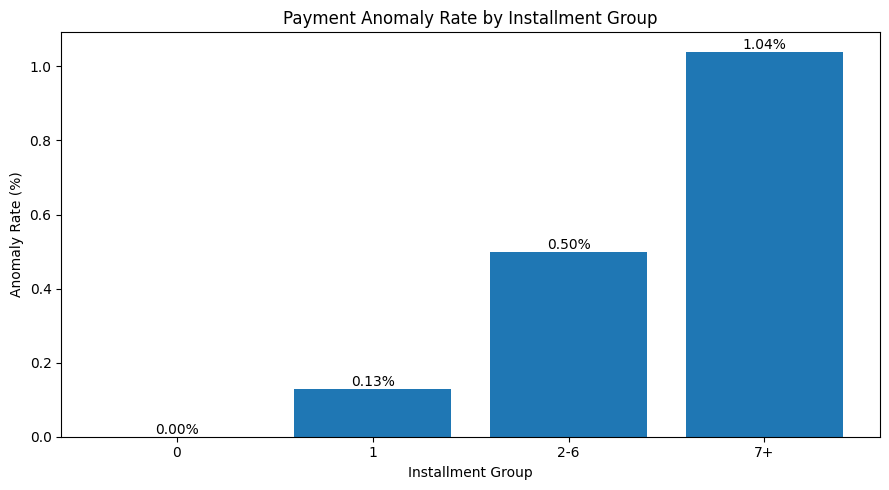

In [ ]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    anomaly_by_installment["installment_group"].astype(str),
    anomaly_by_installment["anomaly_rate"]
)

plt.bar_label(bars, fmt='%.2f%%')

plt.title("Payment Anomaly Rate by Installment Group")
plt.xlabel("Installment Group")
plt.ylabel("Anomaly Rate (%)")

plt.tight_layout()
plt.show()

### Payment Anomaly Rate — Visualization Insights

**Objective:**

Memvisualisasikan perbandingan tingkat anomali pembayaran berdasarkan kelompok cicilan maksimum.

**Key Findings:**

- Kelompok cicilan `1` memiliki anomaly rate sebesar 0,13%.
- Kelompok cicilan `2-6` memiliki anomaly rate sebesar 0,50%.
- Kelompok cicilan `7+` memiliki anomaly rate tertinggi sebesar 1,04%.
- Kelompok cicilan `0` memiliki anomaly rate 0%, tetapi hanya mencakup dua pesanan.

**Visualization Insight:**

Grafik menunjukkan pola peningkatan anomaly rate pada kelompok cicilan 1, 2–6, dan 7+.

Penggunaan anomaly rate membantu mengurangi bias akibat perbedaan volume pesanan antar kelompok. Kelompok dengan jumlah anomali terbanyak belum tentu memiliki tingkat anomali tertinggi.

**Business Interpretation:**

Kelompok cicilan 7+ dapat menjadi prioritas investigasi lebih lanjut karena menunjukkan proporsi anomali tertinggi dalam analisis ini.

Namun, pola tersebut tidak membuktikan bahwa cicilan panjang menyebabkan anomali pembayaran.

**Limitations:**

Anomali didefinisikan sebagai selisih antara nilai pembayaran dan nilai transaksi yang diharapkan. Perbedaan tersebut belum tentu merupakan kesalahan atau kegagalan pembayaran.

Analisis belum mempertimbangkan faktor lain seperti nilai transaksi, metode pembayaran, dan karakteristik produk.

**Next Analysis:**

Mengevaluasi hubungan antara nilai transaksi dan anomali pembayaran untuk mengetahui apakah perbedaan tingkat anomali antar kelompok cicilan mungkin berkaitan dengan besarnya transaksi.


In [ ]:
transactions_installments.groupby("is_anomaly")[
    "expected_payment"
].describe().sort_values("mean", ascending=False)

,count,mean,std,min,25%,50%,75%,max
is_anomaly,,,,,,,,
1.0,381.0,188.283517,275.714912,17.38,59.96,106.87,221.7000,2913.48
0.0,98284.0,160.470410,220.221033,9.59,61.99,105.29,176.7625,13664.08


In [ ]:
transactions_installments.groupby("is_anomaly")[
    "expected_payment"
].apply(lambda x: x.isna().sum())

,expected_payment
is_anomaly,
0.0,0
1.0,0


In [ ]:
transactions_installments.nlargest(
    10, "expected_payment"
)[
    ["order_id", "expected_payment", "is_anomaly", "max_installments"]
]

,order_id,expected_payment,is_anomaly,max_installments
13390,03caa2c082116e1d31e67e9ae3700499,13664.08,0.0,1.0
66599,736e1922ae60d0d6a89247b851902527,7274.88,0.0,1.0
22171,0812eb902a67711a1cb742b3cdaa65ae,6929.31,0.0,8.0
28326,fefacc66af859508bf1a7934eab1e97f,6922.21,0.0,1.0
3508,f5136e38d1a14a4dbd87dff67da82701,6726.66,0.0,1.0
32322,2cc9089445046817a7539d90805e6e5a,6081.54,0.0,1.0
53352,a96610ab360d42a2e5335a3998b4718a,4950.34,0.0,10.0
41086,b4c4b76c642808cbe472a32b86cddc95,4809.44,0.0,5.0
40327,199af31afc78c699f0dbf71fb178d4d4,4764.34,0.0,8.0
40342,8dbc85d1447242f3b127dda390d56e19,4681.78,0.0,8.0


### Transaction Value vs Payment Anomaly — Descriptive Analysis

**Objective:**

Membandingkan nilai transaksi antara pesanan yang mengalami anomali pembayaran dan pesanan non-anomali.

**Key Findings:**

- Kelompok non-anomali memiliki rata-rata nilai transaksi R$160,47 dan median R$105,29.
- Kelompok anomali memiliki rata-rata nilai transaksi R$188,28 dan median R$106,87.
- Rata-rata nilai transaksi kelompok anomali sekitar 17,33% lebih tinggi dibandingkan kelompok non-anomali.
- Perbedaan median kedua kelompok hanya sekitar 1,50%.
- Nilai transaksi maksimum kelompok non-anomali mencapai R$13.664,08, sedangkan kelompok anomali mencapai R$2.913,48.

**Business Insight:**

Pesanan anomali menunjukkan rata-rata nilai transaksi lebih tinggi, tetapi nilai median kedua kelompok relatif berdekatan.

Perbedaan antara mean dan median menunjukkan bahwa distribusi nilai transaksi perlu diperiksa lebih lanjut, terutama kemungkinan pengaruh transaksi bernilai tinggi.

**Data Quality & Limitations:**

- Transaksi bernilai ekstrem belum tentu merupakan kesalahan data.
- Anomali pembayaran didefinisikan berdasarkan selisih nilai pembayaran, bukan kegagalan pembayaran.
- Analisis deskriptif ini belum membuktikan bahwa nilai transaksi yang lebih tinggi menyebabkan anomali.
- Perbedaan ukuran sampel antara kelompok anomali dan non-anomali perlu dipertimbangkan.

**Next Analysis:**

Memvisualisasikan distribusi nilai transaksi menggunakan boxplot untuk membandingkan median, sebaran, dan outlier pada kedua kelompok.

In [ ]:
normal_values = transactions_installments.loc[
    transactions_installments["is_anomaly"] == 0,
    "expected_payment"
].dropna()

anomaly_values = transactions_installments.loc[
    transactions_installments["is_anomaly"] == 1,
    "expected_payment"
].dropna()

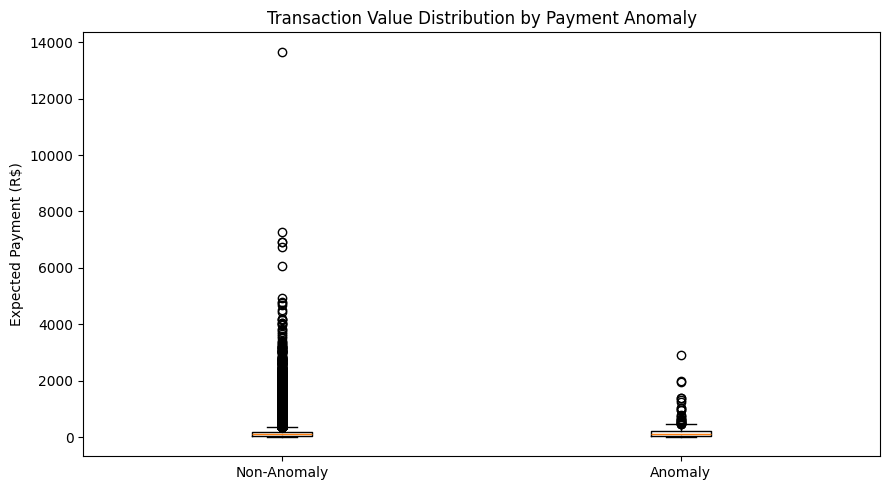

In [ ]:
#boxplot
plt.figure(figsize=(9, 5))

plt.boxplot(
    [normal_values, anomaly_values],
    tick_labels=["Non-Anomaly", "Anomaly"]
)

plt.title("Transaction Value Distribution by Payment Anomaly")
plt.ylabel("Expected Payment (R$)")

plt.tight_layout()
plt.show()

In [ ]:
transactions_installments.groupby("is_anomaly")[
    "expected_payment"
].quantile([0.25, 0.50, 0.75])

is_anomaly      
0.0         0.25     61.9900
            0.50    105.2900
            0.75    176.7625
1.0         0.25     59.9600
            0.50    106.8700
            0.75    221.7000
Name: expected_payment, dtype: float64

In [ ]:
Q1 = transactions_installments.groupby("is_anomaly")["expected_payment"].quantile(0.25)
Q3 = transactions_installments.groupby("is_anomaly")["expected_payment"].quantile(0.75)
IQR = Q3 - Q1

# Lakukan sorting pada Series IQR terlebih dahulu sebelum dicetak
sorted_iqr = IQR.sort_values(ascending=False)
print(sorted_iqr)

is_anomaly
1.0    161.7400
0.0    114.7725
Name: expected_payment, dtype: float64


### Transaction Value Distribution — Boxplot Analysis

**Objective:**

Membandingkan distribusi nilai transaksi antara kelompok pesanan anomali dan non-anomali menggunakan boxplot dan statistik kuartil.

**Key Findings:**

- Kelompok non-anomali memiliki Q1 sebesar 61,99, median 105,29, dan Q3 176,76.
- Kelompok anomali memiliki Q1 sebesar 59,96, median 106,87, dan Q3 221,70.
- IQR kelompok non-anomali sebesar 114,77, sedangkan kelompok anomali sebesar 161,74.
- Kelompok anomali memiliki sebaran 50% data bagian tengah yang lebih lebar.
- Nilai transaksi ekstrem menyebabkan kotak boxplot terlihat kecil ketika seluruh rentang nilai ditampilkan.

**Business Insight:**

Meskipun median nilai transaksi kedua kelompok relatif sama, kelompok anomali memiliki variasi nilai transaksi yang lebih besar pada rentang antarkuartil.

Temuan ini menunjukkan bahwa distribusi nilai transaksi perlu dipertimbangkan ketika mengevaluasi karakteristik pesanan dengan anomali pembayaran.

**Limitations:**

Perbedaan distribusi tidak membuktikan bahwa nilai transaksi yang lebih tinggi menyebabkan anomali. Transaksi bernilai ekstrem juga belum tentu merupakan kesalahan pencatatan.

**Next Analysis:**

Memperbaiki visualisasi boxplot agar distribusi utama kedua kelompok dapat dibandingkan dengan lebih jelas.

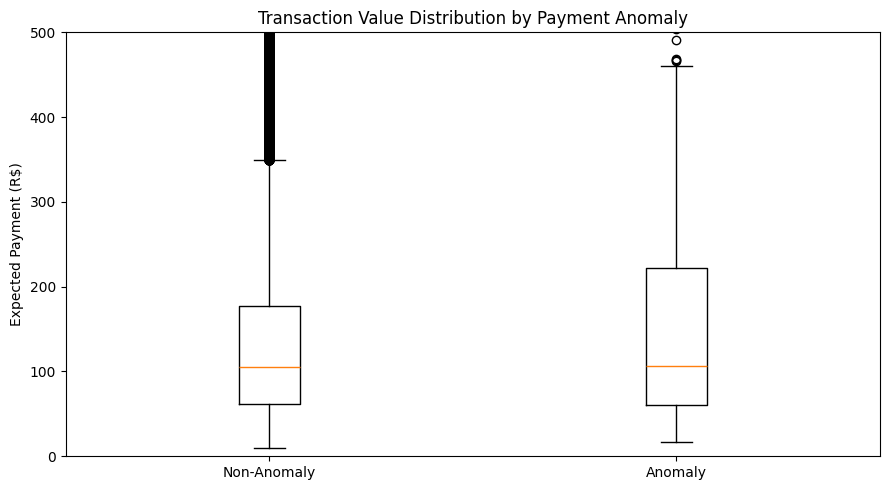

In [ ]:
plt.figure(figsize=(9, 5))

plt.boxplot(
    [normal_values, anomaly_values],
    tick_labels=["Non-Anomaly", "Anomaly"]
)

plt.ylim(0, 500)

plt.title("Transaction Value Distribution by Payment Anomaly")
plt.ylabel("Expected Payment (R$)")

plt.tight_layout()
plt.show()

### Boxplot Visualization — Adjusted Y-Axis

**Objective:**

Meningkatkan keterbacaan visualisasi distribusi nilai transaksi antara kelompok anomali dan non-anomali.

**Method:**

Menggunakan `plt.ylim(0, 500)` untuk membatasi rentang sumbu Y yang ditampilkan tanpa menghapus transaksi bernilai tinggi dari dataset.

**Key Findings:**

- Pembatasan sumbu Y membuat perbedaan kuartil dan median lebih mudah diamati.
- Median kedua kelompok relatif berdekatan.
- Kelompok anomali memiliki IQR lebih besar (161,74) dibandingkan kelompok non-anomali (114,77).
- Transaksi di atas (500) tetap disertakan dalam perhitungan statistik, meskipun tidak seluruhnya terlihat pada grafik.

**Business Insight:**

Kelompok anomali menunjukkan variasi nilai transaksi yang lebih besar pada 50% data bagian tengah, meskipun median kedua kelompok hampir sama.

**Limitation:**

Pembatasan sumbu Y menyembunyikan sebagian rentang nilai ekstrem dari tampilan. Oleh karena itu, batas visualisasi perlu dijelaskan agar grafik tidak menimbulkan interpretasi yang keliru.

In [ ]:
q1 = transactions_installments.groupby("is_anomaly")[
    "expected_payment"
].quantile(0.25)

q3 = transactions_installments.groupby("is_anomaly")[
    "expected_payment"
].quantile(0.75)

iqr = q3 - q1

upper_bound = q3 + 1.5 * iqr

upper_bound.round(2)

,expected_payment
is_anomaly,
0.0,348.92
1.0,464.31


In [ ]:
hitung1 = (normal_values > upper_bound.loc[0.0]).sum()
hitung2 = (normal_values > upper_bound.loc[1.0]).sum()
hitung3 = (anomaly_values > upper_bound.loc[0.0]).sum()
hitung4 = (anomaly_values > upper_bound.loc[1.0]).sum()
print("normal_values 0 =", hitung1)
print("normal_values 1 =", hitung2)
print("anomaly_values 0 =", hitung3)
print("anomaly_values 1 =", hitung4)

normal_values 0 = 7753
normal_values 1 = 4685
anomaly_values 0 = 39
anomaly_values 1 = 27


### Transaction Value Outlier Detection — IQR Method

**Objective:**

Mengidentifikasi transaksi bernilai tinggi yang berada di luar batas atas distribusi nilai transaksi pada kelompok anomali dan non-anomali.

**Methodology:**

Menggunakan metode Interquartile Range (IQR) dengan rumus:

Upper Bound = Q3 + 1.5 × IQR

Batas atas dihitung secara terpisah untuk setiap kelompok.

**Key Findings:**

- Kelompok non-anomali memiliki upper bound 348,92, dengan 7.753 transaksi di atas batas tersebut.
- Kelompok anomali memiliki upper bound 464,31, dengan 27 transaksi di atas batas tersebut.
- Kelompok anomali memiliki batas outlier lebih tinggi karena sebaran nilai transaksi bagian tengah lebih lebar.

**Business Insight:**

Transaksi bernilai tinggi ditemukan pada kedua kelompok. Namun, jumlah outlier absolut belum cukup untuk menentukan kelompok mana yang memiliki proporsi outlier lebih tinggi karena ukuran kelompok berbeda.

**Limitations:**

Outlier berdasarkan nilai transaksi tidak otomatis menunjukkan kesalahan pencatatan maupun anomali pembayaran. Transaksi bernilai ekstrem dapat merupakan aktivitas pembelian yang sah.

**Next Analysis:**

Menghitung persentase upper outlier pada masing-masing kelompok untuk melakukan perbandingan yang lebih proporsional.

In [ ]:
hitung1 = (normal_values > upper_bound.loc[0.0]).sum()
hitung4 = (anomaly_values > upper_bound.loc[1.0]).sum()

# rumus persentase: (jumlah outlier / total data) * 100
normal_outlier_rate = (hitung1 / len(normal_values)) * 100
anomaly_outlier_rate = (hitung4 / len(anomaly_values)) * 100

# Melakukan pembulatan dengan fungsi round() sebelum di-print
print("normal_outlier_rate = ", round(normal_outlier_rate, 2))
print("anomaly_outlier_rate = ", round(anomaly_outlier_rate, 2))

normal_outlier_rate =  7.89
anomaly_outlier_rate =  7.09


### Transaction Value Outlier Rate Analysis

**Objective:**

Membandingkan proporsi transaksi bernilai tinggi yang dikategorikan sebagai upper outlier pada kelompok anomali dan non-anomali.

**Methodology:**

Outlier ditentukan menggunakan batas Q3 + 1.5 × IQR yang dihitung secara terpisah untuk setiap kelompok.

Outlier rate dihitung dengan membagi jumlah upper outlier dengan total transaksi dalam masing-masing kelompok, kemudian dikalikan 100%.

**Key Findings:**

- Kelompok non-anomali memiliki 7.753 upper outlier dari 98.284 transaksi (7,89%).
- Kelompok anomali memiliki 27 upper outlier dari 381 transaksi (7,09%).
- Kelompok non-anomali memiliki outlier rate sekitar 0,80 poin persentase lebih tinggi.

**Business Insight:**

Transaksi bernilai ekstrem ditemukan pada kedua kelompok. Berdasarkan batas IQR masing-masing, proporsi upper outlier pada kelompok non-anomali sedikit lebih tinggi.

Jumlah outlier absolut tidak cukup untuk membandingkan kelompok dengan ukuran berbeda. Oleh karena itu, outlier rate digunakan untuk memberikan perbandingan yang lebih proporsional.

**Limitations:**

- Batas outlier berbeda antar kelompok sehingga perbandingan ini menggambarkan nilai ekstrem relatif terhadap distribusi masing-masing kelompok.
- Outlier tidak otomatis merupakan kesalahan pencatatan.
- Outlier nilai transaksi tidak sama dengan anomali pembayaran.
- Analisis ini bersifat deskriptif dan tidak membuktikan hubungan sebab-akibat.

**Next Analysis:**

Membuat visualisasi outlier rate untuk memperjelas perbandingan proporsi transaksi bernilai ekstrem.

In [ ]:
outlier_rates = [
    normal_outlier_rate,
    anomaly_outlier_rate
]

groups = ["Non-Anomaly", "Anomaly"]

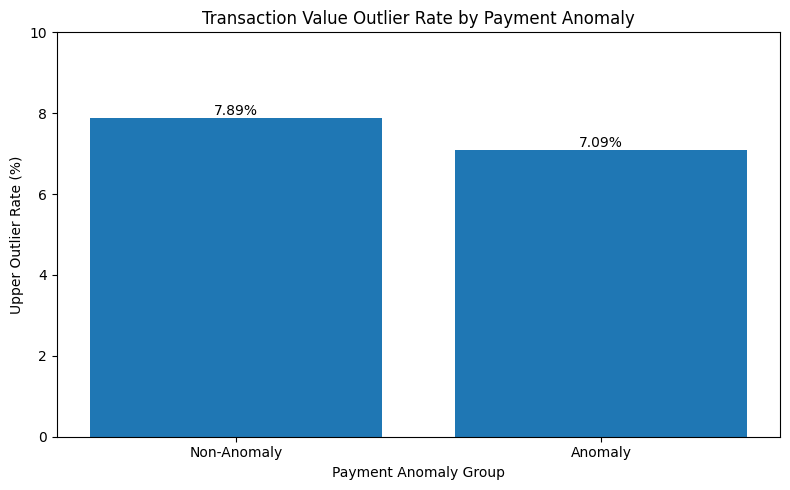

In [ ]:
plt.figure(figsize=(8, 5))

bars = plt.bar(groups, outlier_rates)

plt.title("Transaction Value Outlier Rate by Payment Anomaly")
plt.xlabel("Payment Anomaly Group")
plt.ylabel("Upper Outlier Rate (%)")
plt.bar_label(bars, fmt='%.2f%%')
plt.ylim(0, 10)

plt.tight_layout()
plt.show()

### Transaction Value Outlier Rate — Visualization Insights

**Objective:**

Memvisualisasikan perbandingan persentase transaksi bernilai ekstrem antara kelompok anomali dan non-anomali.

**Key Findings:**

- Kelompok non-anomali memiliki upper outlier rate sebesar 7,89%.
- Kelompok anomali memiliki upper outlier rate sebesar 7,09%.
- Selisih kedua kelompok sebesar 0,80 poin persentase.

**Business Insight:**

Proporsi transaksi yang berada di atas batas IQR masing-masing kelompok relatif berdekatan.

Meskipun kelompok anomali memiliki rata-rata nilai transaksi dan IQR yang lebih tinggi, kelompok tersebut tidak memiliki upper outlier rate yang lebih tinggi berdasarkan pendekatan ini.

**Methodology:**

Upper outlier ditentukan menggunakan Q3 + 1.5 × IQR secara terpisah untuk setiap kelompok.

**Limitations:**

- Batas upper outlier berbeda antara kelompok anomali dan non-anomali.
- Outlier tidak otomatis menunjukkan kesalahan transaksi.
- Anomali pembayaran tidak sama dengan transaksi bernilai ekstrem.
- Hasil bersifat deskriptif dan tidak menunjukkan hubungan sebab-akibat.

**Next Analysis:**

Mengevaluasi proporsi anomali pembayaran berdasarkan kelompok nilai transaksi menggunakan batas nilai transaksi yang sama untuk seluruh pesanan.

In [ ]:
# menghitung jumlah pesanan berdasarkan kelompok nilai transaksi
transactions_installments["transaction_value_group"] = pd.cut(
    transactions_installments["expected_payment"],
    bins=[0, 100, 200, 500, float("inf")],
    labels=["0-100", "100-200", "200-500", "500+"]
)

In [ ]:
transactions_installments[
    "transaction_value_group"
].value_counts(dropna=False).sort_index()

,count
transaction_value_group,
0-100,46905
100-200,31668
200-500,15860
500+,4233
NaN,775


In [ ]:
transactions_installments.groupby(
    "transaction_value_group",
    observed=True
)["is_anomaly"].value_counts(dropna=False)

transaction_value_group  is_anomaly
0-100                    0.0           46727
                         1.0             178
100-200                  0.0           31572
                         1.0              95
                         NaN               1
200-500                  0.0           15775
                         1.0              85
500+                     0.0            4210
                         1.0              23
Name: count, dtype: int64

### Transaction Value Segmentation — Order Distribution

**Objective:**

Mengelompokkan pesanan berdasarkan nilai transaksi untuk memahami distribusi volume pesanan dan mempersiapkan analisis payment anomaly rate.

**Methodology:**

Nilai transaksi (`expected_payment`) dikelompokkan menggunakan `pd.cut()` menjadi empat kategori:

- 0–100
- 100–200
- 200–500
- 500+

**Key Findings:**

- Kelompok 0–100 memiliki 46.905 pesanan.
- Kelompok 100–200 memiliki 31.668 pesanan.
- Kelompok 200–500 memiliki 15.860 pesanan.
- Kelompok 500+ memiliki 4.233 pesanan.
- Sebanyak 775 pesanan tidak memiliki nilai transaksi yang dapat dikelompokkan.

**Business Insight:**

Volume pesanan terbesar terkonsentrasi pada kelompok nilai transaksi rendah, khususnya R$0–100.

Namun, kelompok dengan volume pesanan terbesar belum tentu memiliki tingkat anomali pembayaran tertinggi. Analisis lanjutan diperlukan untuk membandingkan proporsi anomali pada setiap kelompok.

**Limitations:**

Batas kategori nilai transaksi ditentukan untuk kebutuhan eksplorasi dan bukan merupakan segmentasi resmi Olist.

**Next Analysis:**

Menghitung jumlah pesanan yang dapat dievaluasi, jumlah pesanan anomali, dan anomaly rate pada setiap kelompok nilai transaksi.

In [ ]:
anomaly_by_value = transactions_installments.groupby(
    "transaction_value_group",
    observed=True
).agg(
    total_orders=("order_id", "count"),
    evaluated_orders=("is_anomaly", "count"),
    anomaly_orders=("is_anomaly", "sum")
).reset_index()

anomaly_by_value

,transaction_value_group,total_orders,evaluated_orders,anomaly_orders
0,0-100,46905,46905,178.0
1,100-200,31668,31667,95.0
2,200-500,15860,15860,85.0
3,500+,4233,4233,23.0


In [ ]:
anomaly_by_value[
    ["total_orders", "evaluated_orders", "anomaly_orders"]
].sum()

,0
total_orders,98666.0
evaluated_orders,98665.0
anomaly_orders,381.0


In [ ]:
anomaly_by_value["anomaly_rate"] = (
    anomaly_by_value["anomaly_orders"] / anomaly_by_value["evaluated_orders"] * 100
).round(2)

anomaly_by_value

,transaction_value_group,total_orders,evaluated_orders,anomaly_orders,anomaly_rate
0,0-100,46905,46905,178.0,0.38
1,100-200,31668,31667,95.0,0.30
2,200-500,15860,15860,85.0,0.54
3,500+,4233,4233,23.0,0.54


In [ ]:
anomaly_by_value["anomaly_rate_precise"] = (
    anomaly_by_value["anomaly_orders"]
    / anomaly_by_value["evaluated_orders"]
    * 100
)

anomaly_by_value[
    ["transaction_value_group", "anomaly_rate_precise"]
].sort_values("anomaly_rate_precise", ascending=False)

,transaction_value_group,anomaly_rate_precise
3,500+,0.543350
2,200-500,0.535939
0,0-100,0.379490
1,100-200,0.299997


### Payment Anomaly Rate by Transaction Value — Key Findings

**Objective:**

Menganalisis hubungan antara kelompok nilai transaksi dan tingkat anomali pembayaran.

**Methodology:**

Pesanan dikelompokkan berdasarkan `expected_payment` menjadi empat kategori: 0–100, 100–200, 200–500, dan 500+.

Anomaly rate dihitung menggunakan jumlah pesanan anomali dibagi jumlah pesanan yang dapat dievaluasi, kemudian dikalikan 100%.

**Key Findings:**

- Kelompok 0–100 memiliki 178 anomali dengan anomaly rate 0,38%.
- Kelompok 100–200 memiliki 95 anomali dengan anomaly rate 0,30%.
- Kelompok 200–500 memiliki 85 anomali dengan anomaly rate 0,54%.
- Kelompok 500+ memiliki 23 anomali dengan anomaly rate 0,54%.
- Sebelum pembulatan, kelompok R$500+ memiliki anomaly rate sedikit lebih tinggi dibandingkan kelompok 200–500.

**Business Insight:**

Kelompok transaksi bernilai tinggi menunjukkan anomaly rate yang lebih tinggi dibandingkan beberapa kelompok bernilai rendah.

Namun, perbedaan antara kelompok 200–500 dan R$500+ sangat kecil sehingga belum dapat disimpulkan sebagai perbedaan risiko yang bermakna secara statistik.

**Limitations:**

- Analisis bersifat deskriptif.
- Perbedaan jumlah pesanan dapat memengaruhi ketidakpastian estimasi.
- Pengujian statistik belum dilakukan.
- Selisih pembayaran tidak otomatis menunjukkan kegagalan transaksi.
- Faktor lain seperti metode pembayaran dan jumlah cicilan belum dikendalikan.

**Recommendation:**

Melakukan pengujian statistik dan analisis lanjutan untuk mengevaluasi apakah hubungan antara nilai transaksi dan anomali pembayaran tetap terlihat setelah mempertimbangkan faktor lainnya.

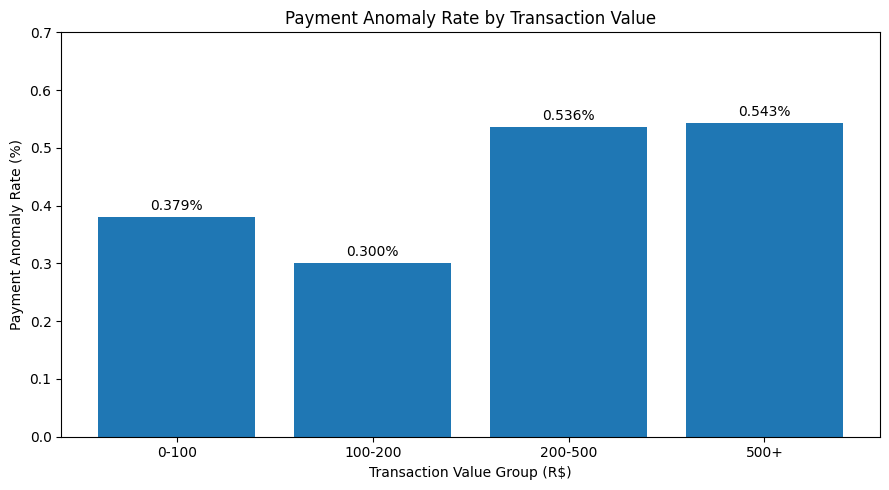

In [ ]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    anomaly_by_value["transaction_value_group"].astype(str),
    anomaly_by_value["anomaly_rate_precise"]
)

plt.title("Payment Anomaly Rate by Transaction Value")
plt.xlabel("Transaction Value Group (R$)")
plt.ylabel("Payment Anomaly Rate (%)")
plt.bar_label(bars, fmt="%.3f%%", padding = 3)

plt.ylim(0, 0.7)

plt.tight_layout()
plt.show()

### Payment Anomaly Rate by Transaction Value — Visualization Insights

**Objective:**

Memvisualisasikan dan membandingkan tingkat anomali pembayaran berdasarkan kelompok nilai transaksi.

**Key Findings:**

- Kelompok 0–100 memiliki anomaly rate sekitar 0,379%.
- Kelompok 100–200 memiliki anomaly rate sekitar 0,300%.
- Kelompok 200–500 memiliki anomaly rate sekitar 0,536%.
- Kelompok 500+ memiliki anomaly rate sekitar 0,543%.

**Business Insight:**

Anomaly rate tidak meningkat secara konsisten dari kelompok nilai transaksi terendah hingga tertinggi.

Kelompok 100–200 memiliki tingkat anomali terendah, sedangkan kelompok R$500+ memiliki tingkat anomali tertinggi secara numerik.

Perbedaan antara kelompok 200–500 dan R$500+ sangat kecil sehingga diperlukan pengujian statistik sebelum menyimpulkan adanya perbedaan risiko yang bermakna.

**Visualization Approach:**

Menggunakan bar chart dengan label persentase tiga angka desimal untuk memperlihatkan perbedaan kecil yang dapat tersembunyi apabila angka dibulatkan menjadi dua desimal.

**Limitations:**

- Analisis bersifat deskriptif.
- Perbedaan anomaly rate belum diuji secara statistik.
- Faktor lain seperti metode pembayaran, jumlah cicilan, dan karakteristik produk belum dikendalikan.
- Anomali pembayaran tidak otomatis menunjukkan kegagalan transaksi.

**Next Analysis:**

Melakukan pengujian statistik untuk mengevaluasi apakah terdapat hubungan antara kelompok nilai transaksi dan status anomali pembayaran.

In [ ]:
contingency_table = pd.crosstab(
    transactions_installments["transaction_value_group"],
    transactions_installments["is_anomaly"]
)

contingency_table

is_anomaly,0.0,1.0
transaction_value_group,,
0-100,46727,178
100-200,31572,95
200-500,15775,85
500+,4210,23


In [ ]:
print("Total evaluated orders:", contingency_table.values.sum())
print("Total anomaly orders:", contingency_table[1.0].sum())
print("Total non-anomaly orders:", contingency_table[0.0].sum())

Total evaluated orders: 98665
Total anomaly orders: 381
Total non-anomaly orders: 98284


### Statistical Analysis — Contingency Table Preparation

**Objective:**

Menyiapkan contingency table untuk mengevaluasi hubungan antara kelompok nilai transaksi dan status anomali pembayaran.

**Methodology:**

Menggunakan `pd.crosstab()` untuk menghitung jumlah pesanan anomali dan non-anomali pada setiap kelompok nilai transaksi.

**Results:**

| Transaction Value | Non-Anomaly | Anomaly |
|---|---:|---:|
| 0–100 | 46,727 | 178 |
| 100–200 | 31,572 | 95 |
| 200–500 | 15,775 | 85 |
| 500+ | 4,210 | 23 |
| **Total** | **98,284** | **381** |

**Data Validation:**

- Total evaluated orders: 98,665
- Total anomaly orders: 381
- Total non-anomaly orders: 98,284

**Data Quality Consideration:**

Pesanan dengan status anomali `NaN` tidak dimasukkan ke contingency table karena statusnya tidak dapat ditentukan berdasarkan data yang tersedia.

Menganggap nilai `NaN` sebagai non-anomali dapat menyebabkan kesalahan klasifikasi dan memengaruhi hasil analisis.

**Next Step:**

Melakukan Chi-Square Test of Independence untuk mengevaluasi apakah kelompok nilai transaksi dan status anomali pembayaran memiliki hubungan yang signifikan secara statistik.

In [ ]:
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

Chi-Square Statistic: 18.134744027767862
P-value: 0.0004125812381644443
Degrees of Freedom: 3


In [ ]:
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

expected_df.round(2)

is_anomaly,0.0,1.0
transaction_value_group,,
0-100,46723.87,181.13
100-200,31544.72,122.28
200-500,15798.76,61.24
500+,4216.65,16.35


### Chi-Square Test — Transaction Value vs Payment Anomaly

**Objective:**

Menguji apakah terdapat hubungan yang signifikan secara statistik antara kelompok nilai transaksi dan status anomali pembayaran.

**Hypotheses:**

- H₀: Kelompok nilai transaksi dan status anomali pembayaran saling independen.
- H₁: Terdapat hubungan antara kelompok nilai transaksi dan status anomali pembayaran.

**Statistical Method:**

Chi-Square Test of Independence dengan tingkat signifikansi α = 0.05.

**Results:**

- Chi-Square Statistic: 18.1347
- P-value: 0.000413
- Degrees of Freedom: 3
- Evaluated Orders: 98,665

**Statistical Decision:**

Karena p-value < 0.05, H₀ ditolak.

**Interpretation:**

Terdapat bukti statistik bahwa kelompok nilai transaksi dan status anomali pembayaran memiliki hubungan dalam dataset yang dianalisis.

Kelompok 200–500 dan 500+ menunjukkan jumlah anomali aktual lebih tinggi dibandingkan expected frequencies berdasarkan asumsi independensi.

**Assumption Check:**

Seluruh expected frequencies lebih besar dari 5, sehingga syarat umum frekuensi harapan untuk pendekatan Chi-Square terpenuhi.

**Limitations:**

- Statistical significance tidak menunjukkan besarnya hubungan.
- Hubungan statistik tidak membuktikan sebab-akibat.
- Anomali didefinisikan berdasarkan selisih pembayaran, bukan sebagai bukti fraud atau kegagalan transaksi.
- Pengujian ini mengasumsikan observasi pesanan independen.

**Next Step:**

Menghitung Cramér's V untuk mengukur kekuatan hubungan antara kelompok nilai transaksi dan status anomali pembayaran.

In [ ]:
import numpy as np

n = contingency_table.values.sum()

r, c = contingency_table.shape

cramers_v = np.sqrt(
    chi2 / (n * min(r - 1, c - 1))
)

print("Total Observations:", n)
print("Cramér's V:", cramers_v)
print("Cramér's V (rounded):", round(cramers_v, 4))

Total Observations: 98665
Cramér's V: 0.013557329608454518
Cramér's V (rounded): 0.0136


### Effect Size Analysis — Cramér's V

**Objective:**

Mengukur kekuatan hubungan antara kelompok nilai transaksi dan status anomali pembayaran setelah pengujian Chi-Square.

**Statistical Results:**

| Metric | Result |
|---|---|
| Evaluated Orders | 98,665 |
| Chi-Square Statistic | 18.1347 |
| P-value | 0.000413 |
| Degrees of Freedom | 3 |
| Cramér's V | 0.0136 |

**Key Findings:**

Chi-Square Test menunjukkan adanya hubungan yang signifikan secara statistik antara kelompok nilai transaksi dan status anomali pembayaran (p < 0.05).

Namun, nilai Cramér's V sebesar 0.0136 menunjukkan bahwa kekuatan asosiasi antara kedua variabel sangat lemah.

**Business Insight:**

Meskipun terdapat bukti hubungan statistik, kelompok nilai transaksi saja belum cukup kuat untuk digunakan sebagai indikator utama dalam mengidentifikasi anomali pembayaran.

Analisis lanjutan diperlukan untuk memahami apakah metode pembayaran, jumlah cicilan, atau karakteristik transaksi lainnya memiliki hubungan yang lebih kuat dengan anomali pembayaran.

**Limitations:**

- Statistical significance tidak selalu menunjukkan dampak praktis yang besar.
- Cramér's V mengukur kekuatan asosiasi, bukan hubungan sebab-akibat.
- Hasil tidak membuktikan bahwa nilai transaksi menyebabkan anomali pembayaran.
- Analisis menggunakan kelompok nilai transaksi, bukan seluruh informasi nilai transaksi kontinu.

**Recommendation:**

Melakukan analisis multivariat untuk mengevaluasi hubungan beberapa karakteristik transaksi dengan status anomali pembayaran secara bersamaan.

In [ ]:
statistical_summary = anomaly_by_value[
    [
        "transaction_value_group",
        "evaluated_orders",
        "anomaly_orders",
        "anomaly_rate_precise"
    ]
].copy()

statistical_summary = statistical_summary.rename(
    columns={
        "transaction_value_group": "transaction_group",
        "anomaly_rate_precise": "anomaly_rate_pct"
    }
)

statistical_summary["anomaly_rate_pct"] = (
    statistical_summary["anomaly_rate_pct"].round(3)
)

statistical_summary

,transaction_group,evaluated_orders,anomaly_orders,anomaly_rate_pct
0,0-100,46905,178.0,0.379
1,100-200,31667,95.0,0.300
2,200-500,15860,85.0,0.536
3,500+,4233,23.0,0.543


### Payment Anomaly Analysis — Statistical Summary

**Objective:**

Menyusun ringkasan hasil analisis anomali pembayaran berdasarkan kelompok nilai transaksi untuk mendukung pengambilan keputusan bisnis.

**Summary Results:**

| Transaction Value | Evaluated Orders | Anomaly Orders | Anomaly Rate |
|---|---:|---:|---:|
| 0–100 | 46,905 | 178 | 0.379% |
| 100–200 | 31,667 | 95 | 0.300% |
| 200–500 | 15,860 | 85 | 0.536% |
| 500+ | 4,233 | 23 | 0.543% |

**Statistical Findings:**

- Chi-Square Statistic: 18.1347
- P-value: 0.000413
- Cramér's V: 0.0136

**Key Insights:**

1. Kelompok 500+ memiliki anomaly rate tertinggi secara numerik, yaitu 0.543%.
2. Kelompok 0–100 memiliki jumlah pesanan anomali terbanyak, yaitu 178 pesanan.
3. Chi-Square Test menunjukkan adanya hubungan yang signifikan secara statistik antara kelompok nilai transaksi dan status anomali pembayaran.
4. Cramér's V menunjukkan bahwa kekuatan hubungan tersebut sangat lemah.

**Business Implications:**

Anomaly rate dan jumlah anomali perlu dianalisis secara bersamaan.

Anomaly rate membantu membandingkan proporsi anomali antar kelompok, sedangkan jumlah anomali membantu memahami volume kasus yang mungkin memerlukan pemeriksaan.

Perusahaan belum memiliki dasar yang cukup untuk memprioritaskan kelompok 500+ hanya berdasarkan anomaly rate tertinggi.

**Recommendations:**

- Mempertimbangkan jumlah anomali, anomaly rate, dan potensi dampak finansial secara bersamaan.
- Menganalisis karakteristik pembayaran lain, termasuk metode pembayaran dan jumlah cicilan.
- Melakukan analisis lanjutan sebelum menetapkan prioritas pemeriksaan transaksi.

**Limitations:**

Hasil analisis menunjukkan asosiasi statistik, bukan hubungan sebab-akibat. Anomali pembayaran yang teridentifikasi juga tidak otomatis menunjukkan fraud atau kerugian finansial.

***Executive Summary — Payment Anomaly Analysis***
OLIST E-COMMERCE · PAYMENT ANALYSIS
Payment Anomaly Analysis
Evaluated orders
98.665

Anomalies
381

Overall anomaly rate
0,386%



Main finding

Kelompok nilai transaksi berhubungan secara signifikan dengan status anomali pembayaran (p = 0,000413), tetapi kekuatan hubungannya sangat lemah (Cramér's V = 0,0136).

Business recommendation

Jangan menggunakan nilai transaksi sebagai satu-satunya indikator prioritas pemeriksaan. Kombinasikan dengan karakteristik pembayaran dan besarnya selisih transaksi.

In [ ]:
transactions_installments["abs_payment_difference"] = (
    transactions_installments["payment_difference"].abs()
)
#.abs() mencegah selisih positif dan negatif saling meniadakan

In [ ]:
financial_exposure = (
    transactions_installments[
        transactions_installments["is_anomaly"] == 1.0
    ]
    .groupby("transaction_value_group", observed=True)
    .agg(
        anomaly_orders=("order_id", "count"),
        total_abs_difference=("abs_payment_difference", "sum"),
        avg_abs_difference=("abs_payment_difference", "mean"),
        max_abs_difference=("abs_payment_difference", "max")
    )
    .reset_index()
)

financial_exposure

,transaction_value_group,anomaly_orders,total_abs_difference,avg_abs_difference,max_abs_difference
0,0-100,178,916.20,5.147191,19.59
1,100-200,95,899.78,9.471368,51.62
2,200-500,85,1194.26,14.050118,119.01
3,500+,23,259.76,11.293913,182.81


### Financial Exposure Analysis — Payment Discrepancies

**Objective:**

Mengukur besarnya selisih pembayaran pada pesanan anomali berdasarkan kelompok nilai transaksi.

**Methodology:**

Menggunakan nilai absolut `payment_difference` untuk menghitung total, rata-rata, dan maksimum selisih pembayaran pada setiap kelompok.

**Results:**

| Transaction Value | Anomaly Orders | Total Absolute Difference | Average Absolute Difference |
|---|---:|---:|---:|
| 0–100 | 178 | 916.20 | 5.15 |
| 100–200 | 95 | 899.78 | 9.47 |
| 200–500 | 85 | 1,194.26 | 14.05 |
| 500+ | 23 | 259.76 | 11.29 |
| **Total** | **381** | **3,270.00** | — |

**Key Findings:**

- Kelompok 200–500 memiliki total absolute payment difference terbesar, yaitu 1,194.26.
- Kelompok 0–100 memiliki jumlah anomali terbanyak, yaitu 178 pesanan.
- Kelompok 500+ memiliki total absolute payment difference terkecil, tetapi mencatat selisih individual terbesar sebesar 182.81.
- Jumlah anomali yang lebih tinggi tidak selalu menghasilkan total selisih pembayaran yang lebih besar.

**Business Insight:**

Evaluasi anomali pembayaran perlu mempertimbangkan jumlah kejadian, tingkat anomali, dan besarnya selisih pembayaran secara bersamaan.

Kelompok 200–500 layak mendapat perhatian lebih lanjut karena memiliki akumulasi selisih pembayaran terbesar dalam analisis ini.

**Limitations:**

Total absolute payment difference merupakan ukuran besarnya ketidaksesuaian pembayaran, bukan bukti kerugian aktual, fraud, atau kegagalan transaksi.

**Recommendation:**

Melakukan investigasi terhadap pesanan dengan selisih pembayaran terbesar serta memeriksa kemungkinan penyebab perbedaan, termasuk metode pembayaran dan aturan pencatatan transaksi.

Latihan 7I — Tahap 5B: Financial Exposure Contribution

In [ ]:
financial_exposure["exposure_share_pct"] = (
    financial_exposure["total_abs_difference"]
    / financial_exposure["total_abs_difference"].sum()
    * 100
).round(2)

financial_exposure[
    [
        "transaction_value_group",
        "anomaly_orders",
        "total_abs_difference",
        "exposure_share_pct"
    ]
]

,transaction_value_group,anomaly_orders,total_abs_difference,exposure_share_pct
0,0-100,178,916.20,28.02
1,100-200,95,899.78,27.52
2,200-500,85,1194.26,36.52
3,500+,23,259.76,7.94


In [ ]:
print(
    "Total absolute difference:",
    financial_exposure["total_abs_difference"].sum()
)

print(
    "Total exposure share:",
    financial_exposure["exposure_share_pct"].sum()
)

Total absolute difference: 3270.0000000000023
Total exposure share: 100.0


- Payment discrepancy adalah selisih antara pembayaran aktual dan nilai pembayaran yang diharapkan.
- Financial loss adalah kerugian finansial yang benar-benar dialami perusahaan.
- Absolute payment difference hanya menunjukkan besarnya selisih, tanpa mempertahankan arah positif atau negatif.
- Investigasi lebih lanjut diperlukan untuk menentukan apakah selisih tersebut berasal dari kesalahan pencatatan, penyesuaian transaksi yang sah, atau masalah pembayaran.
Jadi, kelompok R$200–500 memiliki kontribusi selisih absolut terbesar, tetapi belum tentu menyebabkan kerugian finansial terbesar.

### Financial Exposure Contribution — Key Findings

**Objective:**

Mengukur kontribusi setiap kelompok nilai transaksi terhadap total selisih pembayaran absolut pada pesanan anomali.

**Methodology:**

Menghitung persentase kontribusi menggunakan:

`Exposure Share (%) = Group Total Absolute Difference / Overall Total Absolute Difference × 100`

**Results:**

| Transaction Value | Anomaly Orders | Total Absolute Difference | Exposure Share |
|---|---:|---:|---:|
| 0–100 | 178 | 916.20 | 28.02% |
| 100–200 | 95 | 899.78 | 27.52% |
| 200–500 | 85 | 1,194.26 | 36.52% |
| 500+ | 23 | 259.76 | 7.94% |
| **Total** | **381** | **3,270.00** | **100.00%** |

**Key Findings:**

- Kelompok 200–500 memiliki kontribusi selisih pembayaran absolut terbesar, yaitu 36.52%.
- Kelompok 0–100 menyumbang 28.02% dan memiliki jumlah pesanan anomali terbanyak.
- Kelompok 500+ hanya menyumbang 7.94%, meskipun memiliki anomaly rate tertinggi.

**Business Insight:**

Kelompok dengan anomaly rate tertinggi tidak selalu memiliki kontribusi selisih pembayaran absolut terbesar.

Kelompok R$200–500 dapat dipertimbangkan sebagai salah satu prioritas investigasi karena memiliki akumulasi selisih pembayaran terbesar.

**Limitations:**

Total absolute payment difference tidak sama dengan kerugian finansial aktual. Selisih positif dan negatif dihitung berdasarkan nilai absolutnya sehingga arah selisih tidak terlihat dalam metrik ini.

**Recommendation:**

Melakukan investigasi lanjutan terhadap pesanan dengan selisih pembayaran terbesar, termasuk memeriksa arah selisih, metode pembayaran, dan kemungkinan penyesuaian transaksi yang sah.

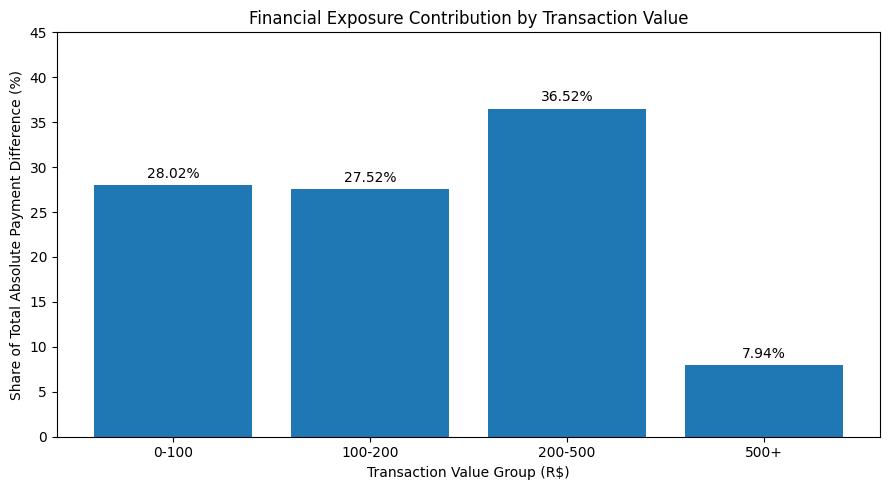

In [ ]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    financial_exposure["transaction_value_group"].astype(str),
    financial_exposure["exposure_share_pct"]
)

plt.title("Financial Exposure Contribution by Transaction Value")
plt.xlabel("Transaction Value Group (R$)")
plt.ylabel("Share of Total Absolute Payment Difference (%)")
plt.bar_label(bars, fmt="%.2f%%",padding = 3)
plt.ylim(0, 45)

plt.tight_layout()
plt.show()

### Financial Exposure Contribution — Visualization Insights

**Objective:**

Memvisualisasikan kontribusi setiap kelompok nilai transaksi terhadap total absolute payment difference dan membandingkannya dengan payment anomaly rate.

**Key Findings:**

- Kelompok 200–500 memiliki exposure share terbesar, yaitu 36.52%.
- Kelompok 0–100 menyumbang 28.02%.
- Kelompok 100–200 menyumbang 27.52%.
- Kelompok 500+ memiliki exposure share terkecil, yaitu 7.94%.

**Comparison with Payment Anomaly Rate:**

Kelompok R$500+ memiliki anomaly rate tertinggi sebesar 0.543%, tetapi kontribusinya terhadap total selisih pembayaran absolut hanya 7.94%.

Sebaliknya, kelompok 200–500 memiliki anomaly rate sebesar 0.536% dan exposure share terbesar sebesar 36.52%.

**Business Insight:**

Anomaly rate dan exposure share memberikan perspektif berbeda.

Anomaly rate menunjukkan proporsi pesanan yang mengalami anomali dalam setiap kelompok, sedangkan exposure share menunjukkan kontribusi kelompok terhadap akumulasi nilai absolut selisih pembayaran.

Kedua metrik perlu dipertimbangkan bersama agar prioritas investigasi tidak hanya ditentukan berdasarkan satu indikator.

**Limitations:**

Total absolute payment difference tidak sama dengan financial loss. Nilai absolut menghilangkan arah positif dan negatif dari selisih pembayaran.

**Recommendation:**

Melakukan analisis lanjutan terhadap arah selisih pembayaran untuk membedakan transaksi dengan pembayaran lebih tinggi dan lebih rendah daripada expected payment.

In [ ]:
transactions_installments["payment_difference"].abs()

,payment_difference
0,0.000000e+00
1,0.000000e+00
2,0.000000e+00
3,0.000000e+00
4,3.552714e-15
...,...
99436,0.000000e+00
99437,0.000000e+00
99438,0.000000e+00
99439,0.000000e+00


In [ ]:
import numpy as np

transactions_installments["discrepancy_direction"] = np.select(
    [
        transactions_installments["payment_difference"] > 0.01,
        transactions_installments["payment_difference"] < -0.01,
        transactions_installments["payment_difference"].abs() <= 0.01
    ],
    [
        "Positive",
        "Negative",
        "No Anomaly"
    ],
    default="Unknown"
)

In [ ]:
transactions_installments[
    "discrepancy_direction"
].value_counts()

,count
discrepancy_direction,
No Anomaly,98284
Unknown,776
Positive,291
Negative,90


In [ ]:
transactions_installments[
    "discrepancy_direction"
]

,discrepancy_direction
0,No Anomaly
1,No Anomaly
2,No Anomaly
3,No Anomaly
4,No Anomaly
...,...
99436,No Anomaly
99437,No Anomaly
99438,No Anomaly
99439,No Anomaly


In [ ]:
print(
    "Total orders:",
    transactions_installments["discrepancy_direction"].count()
)

print(
    "Total anomalies:",
    transactions_installments[
        "discrepancy_direction"
    ].isin(["Positive", "Negative"]).sum()
)
print(
    "Total anomalies positif:",
    transactions_installments[
        "discrepancy_direction"
    ].isin(["Positive"]).sum()
)


print(
    "Total anomalies negatif:",
    transactions_installments[
        "discrepancy_direction"
    ].isin([ "Negative"]).sum()
)
print(
    "Unknown:",
    (
        transactions_installments["discrepancy_direction"]
        == "Unknown"
    ).sum()
)

Total orders: 99441
Total anomalies: 381
Total anomalies positif: 291
Total anomalies negatif: 90
Unknown: 776


### Positive vs Negative Payment Difference — Key Findings

**Objective:**

Mengidentifikasi arah selisih pembayaran untuk membedakan pesanan dengan pembayaran tercatat lebih tinggi dan lebih rendah daripada expected payment.

**Methodology:**

Mengelompokkan pesanan berdasarkan nilai `payment_difference` dengan toleransi R$0.01:

- Positive: `payment_difference > 0.01`
- Negative: `payment_difference < -0.01`
- No Anomaly: `abs(payment_difference) <= 0.01`
- Unknown: nilai selisih pembayaran tidak tersedia.

**Results:**

| Discrepancy Direction | Total Orders |
|---|---:|
| No Anomaly | 98,284 |
| Unknown | 776 |
| Positive | 291 |
| Negative | 90 |
| **Total** | **99,441** |

**Key Findings:**

- Terdapat 381 pesanan dengan payment discrepancy yang melebihi batas toleransi.
- Sebanyak 291 pesanan (76.38% dari anomali) memiliki positive discrepancy.
- Sebanyak 90 pesanan (23.62% dari anomali) memiliki negative discrepancy.
- Sebanyak 776 pesanan tidak dapat dievaluasi karena nilai payment difference tidak tersedia.

**Business Insight:**

Positive discrepancy lebih sering ditemukan dibandingkan negative discrepancy pada pesanan anomali.

Namun, jumlah anomali tidak menunjukkan besarnya nilai finansial dari setiap kelompok.

**Limitations:**

Positive dan negative discrepancy tidak otomatis membuktikan adanya kesalahan pembayaran atau kerugian finansial.

Perbedaan dapat dipengaruhi oleh penyesuaian transaksi, aturan pembayaran, maupun pencatatan data.

**Recommendation:**

Menganalisis distribusi positive dan negative discrepancy berdasarkan kelompok nilai transaksi serta menghitung akumulasi nilai selisih pada setiap kelompok.

In [ ]:
direction_by_value = pd.crosstab(
    transactions_installments["transaction_value_group"],
    transactions_installments["discrepancy_direction"]
)

direction_by_value
# Baris: transaction_value_group
# Kolom: discrepancy_direction
# Nilai: jumlah pesanan

discrepancy_direction,Negative,No Anomaly,Positive,Unknown
transaction_value_group,,,,
0-100,17,46727,161,0
100-200,28,31572,67,1
200-500,35,15775,50,0
500+,10,4210,13,0


In [ ]:
anomaly_direction_by_value = direction_by_value[
    ["Positive", "Negative"]
].copy()

anomaly_direction_by_value

discrepancy_direction,Positive,Negative
transaction_value_group,,
0-100,161,17
100-200,67,28
200-500,50,35
500+,13,10


In [ ]:
print(
    "Total positive:",
    anomaly_direction_by_value["Positive"].sum()
)

print(
    "Total negative:",
    anomaly_direction_by_value["Negative"].sum()
)

print(
    "Total anomalies:",
    anomaly_direction_by_value.to_numpy().sum()
)

Total positive: 291
Total negative: 90
Total anomalies: 381


### Positive vs Negative Discrepancy by Transaction Value — Key Findings

**Objective:**

Menganalisis distribusi positive dan negative payment discrepancy berdasarkan kelompok nilai transaksi.

**Methodology:**

Menggunakan `pd.crosstab()` untuk menghitung jumlah pesanan anomali berdasarkan `transaction_value_group` dan `discrepancy_direction`.

**Results:**

| Transaction Value | Positive | Negative | Total Anomalies |
|---|---:|---:|---:|
| 0–100 | 161 | 17 | 178 |
| 100–200 | 67 | 28 | 95 |
| 200–500 | 50 | 35 | 85 |
| 500+ | 13 | 10 | 23 |
| **Total** | **291** | **90** | **381** |

**Key Findings:**

- Kelompok 0–100 memiliki jumlah positive discrepancy terbanyak, yaitu 161 pesanan.
- Kelompok 200–500 memiliki jumlah negative discrepancy terbanyak, yaitu 35 pesanan.
- Positive discrepancy lebih banyak daripada negative discrepancy pada seluruh kelompok nilai transaksi.
- Secara keseluruhan, terdapat 291 positive discrepancy dan 90 negative discrepancy.

**Business Insight:**

Distribusi arah selisih pembayaran berbeda antar kelompok nilai transaksi.

Kelompok 0–100 mendominasi jumlah positive discrepancy, sedangkan kelompok 200–500 memiliki jumlah negative discrepancy terbesar.

Perbedaan tersebut dapat menjadi dasar untuk menentukan kelompok transaksi yang perlu diperiksa lebih lanjut.

**Limitations:**

Analisis ini hanya menghitung jumlah pesanan dan belum mengukur besarnya nominal selisih pembayaran.

Positive dan negative discrepancy juga belum dapat dianggap sebagai keuntungan atau kerugian finansial aktual.

**Recommendation:**

Menghitung total nominal positive dan negative payment difference pada setiap kelompok nilai transaksi untuk memahami besarnya ketidaksesuaian pembayaran.

In [ ]:
discrepancy_orders = transactions_installments[
    transactions_installments["discrepancy_direction"].isin(
        ["Positive", "Negative"]
    )
].copy()

print("Total anomaly orders:", len(discrepancy_orders))

discrepancy_orders[
    [
        "order_id",
        "transaction_value_group",
        "payment_difference",
        "discrepancy_direction"
    ]
].head()

Total anomaly orders: 381


,order_id,transaction_value_group,payment_difference,discrepancy_direction
464,8adafb3466daa5395694d3a906ff9d40,200-500,-0.02,Negative
867,bb2e64c3040ceb9b7ca2bfc602adca08,200-500,-0.02,Negative
1080,84d6d9710c8af32b5e88f2d1c14ab871,0-100,4.02,Positive
1126,74016effecaa79d592487f6a4ee47d4b,0-100,5.45,Positive
1669,239f380355f65dcb68551f07d16fc4a8,200-500,29.00,Positive


In [ ]:
monetary_direction = (
    discrepancy_orders
    .groupby(
        ["transaction_value_group", "discrepancy_direction"],
        observed=True
    )["payment_difference"]
    .sum()
    .unstack(fill_value=0)
)

monetary_direction

discrepancy_direction,Negative,Positive
transaction_value_group,,
0-100,-45.63,870.57
100-200,-90.21,809.57
200-500,-63.56,1130.70
500+,-0.19,259.57


In [ ]:
print(
    "Total positive difference:",
    monetary_direction["Positive"].sum()
)

print(
    "Total negative difference:",
    monetary_direction["Negative"].sum()
)

print(
    "Net payment difference:",
    monetary_direction.to_numpy().sum()
)

print(
    "Total absolute difference:",
    discrepancy_orders["payment_difference"].abs().sum()
)

Total positive difference: 3070.4100000000003
Total negative difference: -199.59000000000168
Net payment difference: 2870.819999999999
Total absolute difference: 3270.000000000002


### Monetary Value of Positive vs Negative Discrepancies — Key Findings

**Objective:**

Mengukur nominal positive dan negative payment discrepancy berdasarkan kelompok nilai transaksi.

**Methodology:**

Pesanan anomali dikelompokkan berdasarkan `transaction_value_group` dan `discrepancy_direction`. Nilai `payment_difference` dijumlahkan tanpa menggunakan fungsi absolut agar arah selisih tetap dipertahankan.

**Results:**

| Transaction Value | Negative Difference | Positive Difference |
|---|---:|---:|
| 0–100 | −45.63 | 870.57 |
| 100–200 | −90.21 | 809.57 |
| 200–500 | −63.56 | 1,130.70 |
| 500+ | −0.19 | 259.57 |
| **Total** | **−199.59** | **3,070.41** |

**Key Findings:**

- Kelompok 200–500 memiliki total positive payment difference terbesar, yaitu 1,130.70.
- Kelompok 100–200 memiliki total negative payment difference terbesar berdasarkan nilai absolutnya, yaitu 90.21.
- Total positive difference sebesar 3,070.41.
- Total negative difference sebesar −199.59.
- Net payment difference sebesar 2,870.82.
- Total absolute difference sebesar 3,270.00.

**Business Insight:**

Positive payment discrepancy memiliki nominal agregat lebih besar daripada negative payment discrepancy pada data yang dianalisis.

Kelompok 200–500 menjadi kandidat untuk investigasi lebih lanjut karena memiliki nominal positive discrepancy terbesar.

**Limitations:**

Net payment difference tidak dapat langsung dianggap sebagai keuntungan atau kerugian finansial aktual. Selisih pembayaran dapat dipengaruhi oleh penyesuaian transaksi, aturan pembayaran, dan proses pencatatan data.

**Recommendation:**

Memvisualisasikan nominal positive dan negative payment discrepancy secara berdampingan agar stakeholder dapat membandingkan arah dan besarnya selisih pembayaran antar kelompok transaksi.

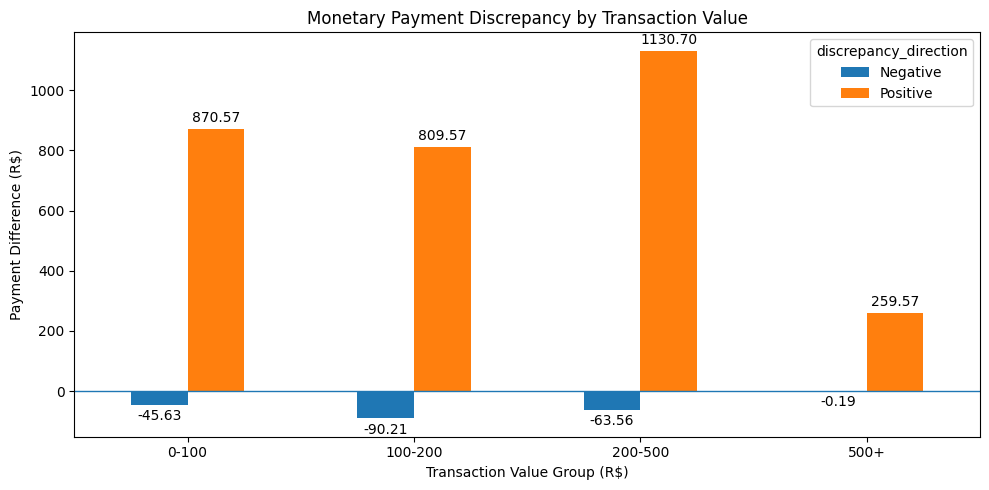

In [ ]:
ax = monetary_direction.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Monetary Payment Discrepancy by Transaction Value")
plt.xlabel("Transaction Value Group (R$)")
plt.ylabel("Payment Difference (R$)")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3
    )

plt.axhline(0, linewidth=1)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Monetary Payment Discrepancy — Visualization Insights

**Objective:**

Memvisualisasikan perbandingan nominal positive dan negative payment discrepancy pada setiap kelompok nilai transaksi.

**Key Findings:**

- Kelompok 200–500 memiliki positive payment difference terbesar sebesar R$1,130.70.
- Kelompok 100–200 memiliki negative payment difference terbesar berdasarkan nilai absolutnya, yaitu 90.21.
- Positive discrepancy lebih besar secara agregat daripada negative discrepancy.
- Garis nol membedakan arah selisih pembayaran positif dan negatif.

**Business Insight:**

Visualisasi menunjukkan bahwa kelompok dengan jumlah pesanan anomali terbanyak belum tentu memiliki nominal selisih pembayaran terbesar.

Kelompok 200–500 menjadi kandidat investigasi untuk positive discrepancy, sedangkan kelompok 100–200 perlu diperhatikan untuk negative discrepancy.

**Comparison with Previous Analysis:**

Tahap 6B menganalisis jumlah pesanan anomali, sedangkan Tahap 6D menganalisis nominal selisih pembayaran.

Kedua analisis memberikan perspektif berbeda dan dapat digunakan bersama untuk mendukung pengambilan keputusan bisnis.

**Limitations:**

Positive dan negative payment discrepancy belum membuktikan keuntungan atau kerugian finansial aktual.

**Recommendation:**

Melakukan pemeriksaan lebih lanjut terhadap transaksi dengan nominal selisih pembayaran yang besar untuk memahami penyebab ketidaksesuaian.

In [ ]:
anomaly_payment_type = (
    anomaly_payments
    .groupby("payment_type")
    .agg(
        total_payment_records=("order_id", "count"),
        unique_orders=("order_id", "nunique")
    )
    .reset_index()
    .sort_values(
        "unique_orders",
        ascending=False
    )
)

anomaly_payment_type

,payment_type,total_payment_records,unique_orders
1,credit_card,356,345
0,boleto,26,26
3,voucher,13,11
2,debit_card,9,9


In [ ]:
payment_type_total = (
    payments
    .groupby("payment_type")
    .agg(
        total_payment_records=("order_id", "count"),
        unique_orders=("order_id", "nunique")
    )
    .reset_index()
)

payment_type_total

,payment_type,total_payment_records,unique_orders
0,boleto,19784,19784
1,credit_card,76795,76505
2,debit_card,1529,1528
3,not_defined,3,3
4,voucher,5775,3866


### Business Insight — Payment Discrepancy by Payment Type

Hasil analisis menunjukkan bahwa credit card memiliki jumlah pesanan anomali terbanyak, yaitu 345 pesanan unik.

Jumlah payment records dapat berbeda dari unique orders karena satu pesanan memungkinkan memiliki lebih dari satu catatan pembayaran.

Namun, jumlah anomali belum cukup untuk menentukan metode pembayaran dengan tingkat anomali tertinggi. Perbandingan perlu mempertimbangkan total pesanan pada masing-masing metode pembayaran.

Oleh karena itu, analisis selanjutnya akan menghitung anomaly rate untuk setiap metode pembayaran.

In [ ]:
anomaly_rate_payment = (
    anomaly_payment_type
    .merge(
        payment_type_total[["payment_type", "unique_orders"]],
        on="payment_type",
        how="right",
        suffixes=("_anomaly", "_total")
    )
)

anomaly_rate_payment

,payment_type,total_payment_records,unique_orders_anomaly,unique_orders_total
0,boleto,26.0,26.0,19784
1,credit_card,356.0,345.0,76505
2,debit_card,9.0,9.0,1528
3,not_defined,NaN,NaN,3
4,voucher,13.0,11.0,3866


In [ ]:
anomaly_rate_payment["anomaly_orders"] = (
    anomaly_rate_payment["unique_orders_anomaly"]
    .fillna(0)
)

anomaly_rate_payment["anomaly_rate"] = (
    anomaly_rate_payment["anomaly_orders"]
    / anomaly_rate_payment["unique_orders_total"]
    * 100
).round(3)

anomaly_rate_payment = anomaly_rate_payment.sort_values(
    "anomaly_rate",
    ascending=False
)

anomaly_rate_payment

,payment_type,total_payment_records,unique_orders_anomaly,unique_orders_total,anomaly_orders,anomaly_rate
2,debit_card,9.0,9.0,1528,9.0,0.589
1,credit_card,356.0,345.0,76505,345.0,0.451
4,voucher,13.0,11.0,3866,11.0,0.285
0,boleto,26.0,26.0,19784,26.0,0.131
3,not_defined,NaN,NaN,3,0.0,0.000


### Business Insight — Anomaly Rate by Payment Type

Hasil analisis menunjukkan bahwa debit card memiliki anomaly rate tertinggi sebesar 0,589%, meskipun hanya terdapat 9 pesanan anomali.

Sebaliknya, credit card memiliki jumlah pesanan anomali terbanyak, yaitu 345 pesanan, tetapi anomaly rate-nya sebesar 0,451%.

Hal ini menunjukkan bahwa jumlah anomali tidak selalu mencerminkan tingkat anomali suatu metode pembayaran.

Anomaly rate memberikan perbandingan yang lebih proporsional karena mempertimbangkan total pesanan pada setiap metode pembayaran.

Catatan: Anomaly rate debit card yang lebih tinggi merupakan indikasi statistik pada dataset ini, bukan bukti bahwa debit card menyebabkan lebih banyak masalah pembayaran. Jumlah anomali debit card juga relatif kecil.

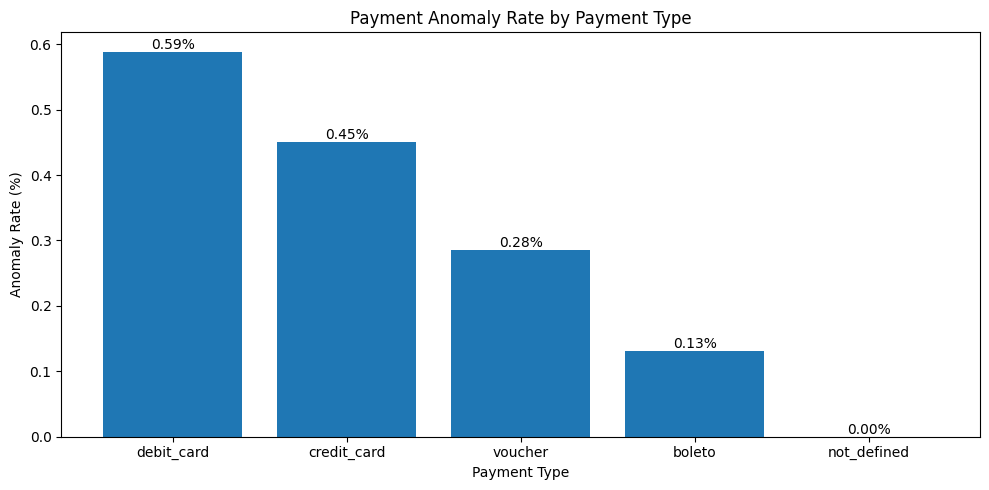

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    anomaly_rate_payment["payment_type"],
    anomaly_rate_payment["anomaly_rate"]
)

plt.title("Payment Anomaly Rate by Payment Type")
plt.xlabel("Payment Type")
plt.ylabel("Anomaly Rate (%)")

plt.xticks(rotation=0)

for i, value in enumerate(anomaly_rate_payment["anomaly_rate"]):
    plt.text(i, value, f"{value:.2f}%", ha="center", va="bottom")

plt.tight_layout()
plt.show()

### Business Insight — Payment Anomaly Rate Visualization

Visualisasi menunjukkan bahwa debit card memiliki anomaly rate tertinggi, sekitar 0,59%, diikuti credit card sebesar 0,45%.

Meskipun credit card memiliki jumlah pesanan anomali paling banyak, debit card memiliki persentase anomali lebih tinggi karena total pesanan debit card jauh lebih sedikit.

Bagi tim Finance dan Payment Operations, hasil ini dapat digunakan sebagai indikator awal untuk menentukan prioritas investigasi transaksi dan mengevaluasi proses pencatatan pembayaran.

Namun, anomaly rate tidak secara langsung membuktikan adanya kesalahan atau fraud. Investigasi lebih lanjut tetap diperlukan.

In [ ]:
transactions_installments["payment_count_group"] = pd.cut(
    transactions_installments["payment_count"],
    bins=[0, 1, 2, float("inf")],
    labels=["1 Payment", "2 Payments", "3+ Payments"]
)

transactions_installments["payment_count_group"].value_counts()

,count
payment_count_group,
1 Payment,96479
2 Payments,2382
3+ Payments,579


In [ ]:
anomaly_by_payment_count = (
    transactions_installments
    .groupby("payment_count_group", observed=True)
    .agg(
        total_orders=("order_id", "count"),
        evaluated_orders=("is_anomaly", "count"),
        anomaly_orders=("is_anomaly", "sum")
    )
    .reset_index()
)

anomaly_by_payment_count

,payment_count_group,total_orders,evaluated_orders,anomaly_orders
0,1 Payment,96479,95729,360.0
1,2 Payments,2382,2364,20.0
2,3+ Payments,579,572,1.0


In [ ]:
anomaly_by_payment_count["anomaly_rate"] = (
    anomaly_by_payment_count["anomaly_orders"]
    / anomaly_by_payment_count["evaluated_orders"]
    * 100
).round(2)

anomaly_by_payment_count

,payment_count_group,total_orders,evaluated_orders,anomaly_orders,anomaly_rate
0,1 Payment,96479,95729,360.0,0.38
1,2 Payments,2382,2364,20.0,0.85
2,3+ Payments,579,572,1.0,0.17


### Business Insight — Payment Records and Anomaly Rate

Hasil analisis menunjukkan bahwa kelompok 2 Payments memiliki anomaly rate tertinggi sebesar 0,85%.

Namun, jumlah payment records yang lebih banyak tidak selalu menunjukkan tingkat anomali yang lebih tinggi.

Payment records merupakan jumlah catatan pembayaran dalam suatu pesanan, sedangkan installments menunjukkan jumlah cicilan yang digunakan untuk membayar transaksi.

Oleh karena itu, kedua variabel tersebut harus dianalisis secara terpisah agar tidak menghasilkan kesimpulan yang keliru.

Temuan ini dapat membantu tim Finance mengevaluasi pola pembayaran multi-record dan menentukan kebutuhan investigasi lebih lanjut.

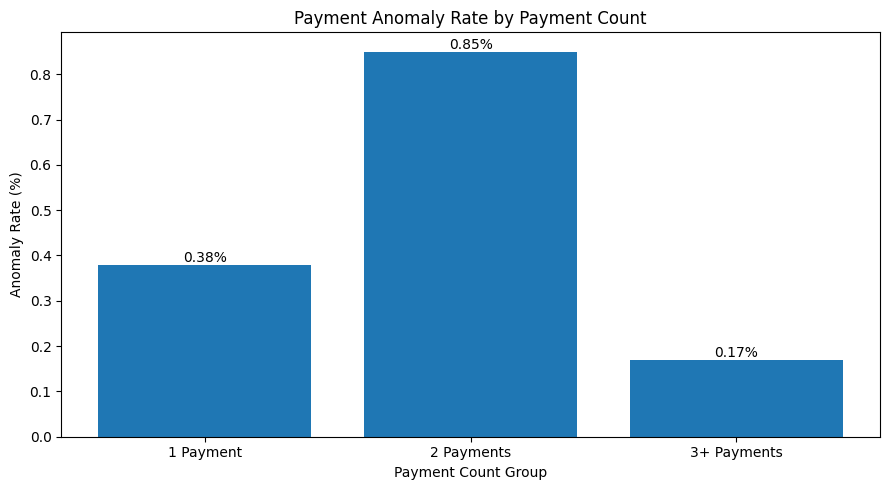

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    anomaly_by_payment_count["payment_count_group"].astype(str),
    anomaly_by_payment_count["anomaly_rate"]
)

plt.title("Payment Anomaly Rate by Payment Count")
plt.xlabel("Payment Count Group")
plt.ylabel("Anomaly Rate (%)")

for i, value in enumerate(anomaly_by_payment_count["anomaly_rate"]):
    plt.text(i, value, f"{value:.2f}%", ha="center", va="bottom")

plt.tight_layout()
plt.show()

### Business Insight — Payment Anomaly Rate by Payment Count

Hasil analisis menunjukkan bahwa kelompok 2 Payments memiliki anomaly rate tertinggi sebesar 0,85%.

Analisis ini memberikan perspektif tambahan mengenai hubungan antara jumlah catatan pembayaran dalam satu pesanan dan kemungkinan terjadinya payment discrepancy.

Jika dibandingkan dengan analisis berdasarkan payment type, perusahaan dapat melihat anomali dari dua sudut pandang, yaitu jenis metode pembayaran dan jumlah catatan pembayaran.

Tim Finance dapat menggunakan kedua informasi tersebut untuk menentukan prioritas pemeriksaan transaksi dan menelusuri kemungkinan penyebab perbedaan nilai pembayaran.

Temuan ini merupakan indikasi untuk investigasi lebih lanjut dan bukan bukti bahwa pembayaran dengan beberapa catatan selalu bermasalah.

### Final Business Insight — Payment Discrepancy Analysis

Berdasarkan hasil analisis, credit card memiliki jumlah pesanan anomali terbanyak sebanyak 345 pesanan. Sementara itu, debit card memiliki anomaly rate tertinggi sebesar 0,589%. Berdasarkan jumlah catatan pembayaran, kelompok 2 Payments memiliki anomaly rate tertinggi sebesar 0,85%.

Hasil ini menunjukkan bahwa payment discrepancy dapat dianalisis dari berbagai perspektif, baik berdasarkan metode pembayaran maupun jumlah catatan pembayaran dalam satu pesanan.

**Rekomendasi untuk Tim Finance:**

1. Memprioritaskan pemeriksaan transaksi debit card karena memiliki anomaly rate tertinggi.
2. Melakukan penelusuran terhadap pesanan dengan 2 payment records untuk memahami kemungkinan penyebab perbedaan pembayaran.
3. Memeriksa pesanan credit card yang memiliki jumlah anomali terbesar untuk mengidentifikasi pola dan potensi masalah pencatatan.
4. Melakukan analisis lebih lanjut menggunakan kombinasi payment type dan payment count untuk mengetahui kelompok transaksi yang memiliki risiko anomali lebih tinggi.

**Kesimpulan:**

Hasil analisis ini dapat digunakan sebagai dasar untuk menentukan prioritas investigasi pembayaran. Namun, payment discrepancy tidak secara otomatis menunjukkan kerugian finansial, kesalahan pencatatan, maupun fraud. Setiap transaksi perlu diverifikasi lebih lanjut oleh tim Finance.

In [ ]:
import pandas as pd

# Daftar DataFrame yang ingin kita periksa
candidate_tables = [
    "orders_clean",
    "customers",
    "order_items",
    "items_products_clean",
    "products",
    "payments",
    "order_transactions",
    "items_agg",
    "payments_agg"
]

# Periksa keberadaan dan struktur DataFrame
for table_name in candidate_tables:

    if table_name in globals():

        df = globals()[table_name]

        if isinstance(df, pd.DataFrame):

            print(f"\n{'='*50}")
            print(f"TABLE: {table_name}")
            print(f"Jumlah baris: {df.shape[0]:,}")
            print(f"Jumlah kolom: {df.shape[1]}")
            print(f"Duplikat seluruh baris: {df.duplicated().sum():,}")
            print(f"Kolom: {list(df.columns)}")

    else:
        print(f"\n{table_name}: Belum tersedia")


TABLE: orders_clean
Jumlah baris: 99,441
Jumlah kolom: 9
Duplikat seluruh baris: 0
Kolom: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivery_days']

TABLE: customers
Jumlah baris: 99,441
Jumlah kolom: 5
Duplikat seluruh baris: 0
Kolom: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

TABLE: order_items
Jumlah baris: 112,650
Jumlah kolom: 7
Duplikat seluruh baris: 0
Kolom: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

TABLE: items_products_clean
Jumlah baris: 112,650
Jumlah kolom: 15
Duplikat seluruh baris: 0
Kolom: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product

In [ ]:
# Pemeriksaan primary key dan foreign key

key_checks = {
    "orders_clean": ["order_id"],
    "customers": ["customer_id"],
    "order_items": ["order_id", "order_item_id"],
    "products": ["product_id"],
    "payments": ["order_id", "payment_sequential"]
}

for table_name, keys in key_checks.items():

    df = globals()[table_name]

    print(f"\n{'='*45}")
    print(f"TABLE: {table_name}")

    for key in keys:
        print(f"\nKolom: {key}")
        print(f"Nilai kosong: {df[key].isna().sum():,}")
        print(f"Nilai unik: {df[key].nunique():,}")

    # Pemeriksaan kombinasi key
    duplicate_keys = df.duplicated(subset=keys).sum()

    print(f"\nDuplikat berdasarkan key {keys}: {duplicate_keys:,}")


TABLE: orders_clean

Kolom: order_id
Nilai kosong: 0
Nilai unik: 99,441

Duplikat berdasarkan key ['order_id']: 0

TABLE: customers

Kolom: customer_id
Nilai kosong: 0
Nilai unik: 99,441

Duplikat berdasarkan key ['customer_id']: 0

TABLE: order_items

Kolom: order_id
Nilai kosong: 0
Nilai unik: 98,666

Kolom: order_item_id
Nilai kosong: 0
Nilai unik: 21

Duplikat berdasarkan key ['order_id', 'order_item_id']: 0

TABLE: products

Kolom: product_id
Nilai kosong: 0
Nilai unik: 32,951

Duplikat berdasarkan key ['product_id']: 0

TABLE: payments

Kolom: order_id
Nilai kosong: 0
Nilai unik: 99,440

Kolom: payment_sequential
Nilai kosong: 0
Nilai unik: 29

Duplikat berdasarkan key ['order_id', 'payment_sequential']: 0


In [ ]:
if "order_reviews" in globals():

    print("DataFrame order_reviews tersedia")
    print("Jumlah baris:", order_reviews.shape[0])
    print("Jumlah kolom:", order_reviews.shape[1])
    print("Kolom:", list(order_reviews.columns))

else:
    print("DataFrame order_reviews belum tersedia")

DataFrame order_reviews belum tersedia


In [ ]:
import os
import shutil
import pandas as pd
from google.colab import files

# ==========================================
# 1. MENENTUKAN DATAFRAME YANG AKAN DIEKSPOR
# ==========================================

tables_to_export = {
    "orders": orders_clean,
    "customers": customers,
    "order_items": order_items,
    "products": products,
    "payments": payments
}

# ==========================================
# 2. MEMBUAT FOLDER EKSPOR
# ==========================================

export_folder = "/content/olist_postgresql_export"

os.makedirs(export_folder, exist_ok=True)

# ==========================================
# 3. MENGEKSPOR SETIAP DATAFRAME KE CSV
# ==========================================

for table_name, df in tables_to_export.items():

    file_path = os.path.join(
        export_folder,
        f"{table_name}.csv"
    )

    df.to_csv(
        file_path,
        index=False,
        encoding="utf-8-sig"
    )

    print(
        f"{table_name}.csv berhasil diekspor | "
        f"{len(df):,} baris"
    )

# ==========================================
# 4. MEMBUAT ZIP DARI SELURUH FILE CSV
# ==========================================

zip_path = shutil.make_archive(
    "/content/olist_postgresql_export",
    "zip",
    export_folder
)

print("\nLokasi file ZIP:", zip_path)

# ==========================================
# 5. MENGUNDUH FILE ZIP
# ==========================================

files.download(zip_path)

orders.csv berhasil diekspor | 99,441 baris
customers.csv berhasil diekspor | 99,441 baris
order_items.csv berhasil diekspor | 112,650 baris
products.csv berhasil diekspor | 32,951 baris
payments.csv berhasil diekspor | 103,886 baris

Lokasi file ZIP: /content/olist_postgresql_export.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Data Preparation for PostgreSQL Integration

Setelah proses data cleaning dan data validation selesai, lima tabel utama dipilih untuk dipindahkan ke PostgreSQL, yaitu orders, customers, order_items, products, dan payments.

Sebelum ekspor, dilakukan pemeriksaan primary key untuk memastikan tidak terdapat nilai kosong maupun duplikat pada kolom identitas utama.

DataFrame kemudian diekspor ke format CSV tanpa menyertakan index Pandas. File CSV digunakan sebagai media pertukaran data antara Google Colab dan PostgreSQL.

**Tujuan:** Menyiapkan dataset yang terstruktur untuk analisis SQL, termasuk customer behavior, repeat purchase, RFM segmentation, dan delivery performance.

### Business Insight #1 — Monthly Orders & Sales Trend

**Objective:** Menganalisis tren jumlah pesanan dan total nilai penjualan bulanan pada transaksi e-commerce Olist.

**Methodology:**
- Menggabungkan tabel `orders` dan `order_items` menggunakan `order_id`.
- Memfilter transaksi dengan status `delivered`.
- Mengelompokkan transaksi berdasarkan bulan menggunakan `DATE_TRUNC()`.
- Menghitung jumlah pesanan unik menggunakan `COUNT(DISTINCT order_id)`.
- Menghitung total penjualan menggunakan penjumlahan harga produk dan biaya pengiriman.

**Key Findings:**
1. November 2017 mencatat jumlah pesanan tertinggi sebanyak 7.289 pesanan.
2. November 2017 juga mencatat total penjualan tertinggi sebesar 1.153.364,20.
3. Januari 2018 berada di peringkat kedua jumlah pesanan, tetapi peringkat kelima total penjualan.
4. Mei 2018 memiliki jumlah pesanan paling sedikit di antara lima bulan dengan penjualan tertinggi.

**Business Insight:**

Jumlah pesanan tidak selalu berbanding lurus dengan nilai penjualan. Perbedaan peringkat antara jumlah pesanan dan total penjualan menunjukkan pentingnya menganalisis nilai rata-rata transaksi pelanggan.

**Next Step:**

Melakukan analisis Average Order Value (AOV) untuk mengetahui rata-rata nilai transaksi setiap bulan.

### Business Insight #2 — Average Order Value (AOV)

**Objective:** Mengidentifikasi bulan dengan rata-rata nilai transaksi tertinggi untuk memahami pola nilai pembelian pelanggan.

**Methodology:**
- Menggabungkan tabel `orders` dan `order_items` menggunakan `order_id`.
- Memfilter pesanan dengan status `delivered`.
- Menghitung total penjualan dari harga produk dan biaya pengiriman.
- Menghitung jumlah pesanan unik.
- Menghitung AOV dengan rumus Total Sales / Total Orders.
- Mengurutkan hasil berdasarkan AOV tertinggi.

**Key Findings:**
1. Oktober 2016 memiliki AOV tertinggi sebesar 175,44 dengan 265 pesanan.
2. Januari 2017 menempati posisi kedua dengan AOV 169,98.
3. September 2017 memiliki AOV 168,93 dengan 4.150 pesanan.
4. November 2017 sebelumnya tercatat sebagai bulan dengan total penjualan dan jumlah pesanan tertinggi, tetapi tidak masuk dalam lima bulan dengan AOV tertinggi.

**Business Insight:**

Bulan dengan total penjualan tertinggi tidak selalu memiliki rata-rata nilai transaksi tertinggi. Oleh karena itu, perusahaan perlu mengevaluasi volume pesanan dan nilai rata-rata transaksi secara bersamaan untuk memahami performa penjualan.

**Limitation:**

Oktober 2016 memiliki jumlah pesanan yang relatif kecil dibandingkan bulan lainnya. Nilai AOV yang tinggi pada periode tersebut perlu dievaluasi dengan mempertimbangkan jumlah transaksi.

**Next Step:**

Menganalisis repeat purchase untuk mengetahui berapa banyak pelanggan yang melakukan pembelian lebih dari satu kali.

### Business Insight #3 — Customer Repeat Purchase Analysis

**Objective:** Mengidentifikasi proporsi pelanggan yang melakukan pembelian berulang untuk mengevaluasi perilaku pembelian dan retensi pelanggan.

**Methodology:**
- Menggabungkan tabel `orders` dan `customers` menggunakan `customer_id`.
- Menggunakan `customer_unique_id` sebagai identitas pelanggan.
- Memfilter pesanan dengan status `delivered`.
- Menghitung jumlah pesanan unik setiap pelanggan.
- Mengelompokkan pelanggan menjadi One-time Customer dan Repeat Customer.
- Menghitung persentase masing-masing kelompok.

**Key Findings:**

| Customer Segment | Total Customers | Percentage |
|---|---:|---:|
| One-time Customer | 90,557 | 97.00% |
| Repeat Customer | 2,801 | 3.00% |
| Total | 93,358 | 100.00% |

**Business Insight:**

Mayoritas pelanggan dalam dataset melakukan pembelian satu kali. Hanya sekitar 3% pelanggan yang melakukan pembelian lebih dari satu kali.

Temuan ini menunjukkan adanya peluang untuk meningkatkan customer retention melalui strategi promosi yang lebih terarah, program loyalitas, voucher pembelian berikutnya, serta peningkatan pengalaman pelanggan.

**Business Recommendation:**

1. Mengembangkan program promosi untuk mendorong pembelian kedua.
2. Memberikan insentif kepada pelanggan yang memiliki riwayat pembelian berulang.
3. Menganalisis karakteristik dan nilai transaksi pelanggan repeat purchase.
4. Mengevaluasi efektivitas program retensi melalui repeat purchase rate.

**Limitation:**

Analisis hanya mencakup pesanan berstatus delivered. Repeat purchase tidak secara otomatis membuktikan loyalitas pelanggan.

**Next Step:**

Menganalisis distribusi frekuensi pembelian untuk mengetahui seberapa sering pelanggan melakukan transaksi berulang.

### Business Insight #4 — Customer Purchase Frequency Analysis

**Objective:** Mengidentifikasi distribusi pelanggan berdasarkan frekuensi pembelian untuk memahami pola transaksi dan menemukan peluang peningkatan customer retention.

**Methodology:**
- Menggabungkan tabel `orders` dan `customers` menggunakan `customer_id`.
- Menggunakan `customer_unique_id` sebagai identitas pelanggan.
- Memfilter pesanan dengan status `delivered`.
- Menghitung jumlah pesanan unik setiap pelanggan.
- Mengelompokkan pelanggan berdasarkan frekuensi pembelian.

**Key Findings:**

| Purchase Frequency | Total Customers | Percentage |
|---|---:|---:|
| 1 Order | 90,557 | 97.00% |
| 2 Orders | 2,573 | 2.76% |
| 3–5 Orders | 218 | 0.23% |
| 6+ Orders | 10 | 0.01% |
| **Total** | **93,358** | **100.00%** |

**Business Insight:**

Sebagian besar pelanggan hanya melakukan satu kali pembelian. Dari total 2.801 repeat customer, sekitar 91.86% hanya melakukan dua kali pembelian.

Hal ini menunjukkan bahwa perusahaan memiliki peluang untuk meningkatkan frekuensi pembelian pelanggan, terutama dengan mendorong pelanggan melakukan transaksi ketiga dan seterusnya.

**Business Recommendation:**
1. Membuat promosi khusus untuk mendorong pembelian kedua.
2. Memberikan program loyalitas kepada pelanggan dengan transaksi berulang.
3. Mengidentifikasi karakteristik pelanggan dengan frekuensi pembelian tinggi.
4. Mengembangkan strategi retensi berdasarkan frekuensi dan nilai transaksi pelanggan.

**Limitation:**

Frekuensi pembelian dihitung berdasarkan pesanan berstatus delivered. Frekuensi transaksi yang tinggi belum tentu menunjukkan nilai pelanggan atau loyalitas yang tinggi.

**Next Step:**

Melakukan analisis Customer Lifetime Value (CLV) sederhana untuk mengidentifikasi pelanggan dengan kontribusi nilai transaksi terbesar.

### Business Insight #5 — Customer Monetary Value Analysis

**Objective:** Mengidentifikasi pelanggan dengan kontribusi nilai pembelian terbesar berdasarkan total pengeluaran dari pesanan yang berhasil diterima.

**Methodology:**
- Menggabungkan tabel `orders`, `customers`, dan `order_items`.
- Menggunakan `customer_unique_id` sebagai identitas pelanggan.
- Menghitung nilai setiap pesanan dari harga produk ditambah ongkos kirim.
- Memfilter pesanan dengan status `delivered`.
- Menghitung total pesanan, total pengeluaran, dan rata-rata nilai pesanan setiap pelanggan.
- Mengurutkan pelanggan berdasarkan total pengeluaran tertinggi.

**Key Findings:**

- Pelanggan dengan pengeluaran tertinggi berasal dari Rio de Janeiro.
- Total pengeluarannya mencapai 13,664.08.
- Pelanggan tersebut hanya melakukan satu pesanan.
- Pelanggan dengan empat pesanan dalam daftar 10 teratas memiliki total pengeluaran 4,655.88.

**Business Insight:**

Frekuensi pembelian tidak selalu sejalan dengan total pengeluaran pelanggan. Pelanggan yang hanya melakukan satu transaksi dapat memberikan kontribusi nilai pembelian lebih besar dibandingkan pelanggan yang melakukan beberapa transaksi.

Oleh karena itu, perusahaan perlu mempertimbangkan frekuensi pembelian dan nilai transaksi secara bersamaan ketika mengidentifikasi pelanggan potensial.

**Business Recommendation:**
1. Mengidentifikasi pelanggan dengan total pengeluaran tinggi untuk program VIP atau loyalitas.
2. Memberikan penawaran yang relevan berdasarkan riwayat transaksi.
3. Mendorong pelanggan dengan nilai pembelian tinggi untuk melakukan transaksi berikutnya.
4. Menggabungkan analisis frekuensi dan nilai pembelian untuk menentukan prioritas retensi pelanggan.

**Limitation:**

Total pengeluaran dihitung berdasarkan harga produk ditambah ongkos kirim dari pesanan berstatus delivered. Nilai ini bukan keuntungan bersih perusahaan karena belum memperhitungkan biaya operasional dan biaya lainnya.

**Next Step:**

Melakukan RFM Analysis untuk mengelompokkan pelanggan berdasarkan Recency, Frequency, dan Monetary.

### RFM Analysis – Step 2: Calculate RFM Metrics

Pada tahap ini dilakukan perhitungan tiga metrik utama RFM untuk setiap pelanggan:

1. **Recency:** Mengukur jumlah hari sejak transaksi terakhir pelanggan.
2. **Frequency:** Mengukur jumlah pesanan yang telah diselesaikan oleh pelanggan.
3. **Monetary:** Mengukur total pengeluaran pelanggan berdasarkan harga produk dan ongkos kirim.

Perhitungan menggunakan `customer_unique_id` sebagai identitas pelanggan dan hanya mempertimbangkan pesanan dengan status `delivered`.

**Business Insight:**

Ketiga metrik memberikan perspektif berbeda dalam memahami perilaku pelanggan. Recency membantu mengidentifikasi aktivitas pembelian terbaru, Frequency menunjukkan intensitas transaksi, sedangkan Monetary menunjukkan kontribusi pengeluaran pelanggan.

Kombinasi ketiga metrik tersebut menjadi dasar untuk mengelompokkan pelanggan berdasarkan nilai dan perilaku pembeliannya.

### RFM Scoring Improvement

Pada tahap validasi, ditemukan bahwa penggunaan `NTILE(5)` untuk Frequency berpotensi memberikan skor berbeda kepada pelanggan yang memiliki jumlah pesanan sama.

Hal ini terjadi karena sebagian besar pelanggan hanya melakukan satu kali pembelian.

Untuk mengatasi masalah tersebut, metode scoring diperbaiki:
- Recency menggunakan `PERCENT_RANK()` dengan urutan descending.
- Frequency menggunakan kategori berdasarkan jumlah pesanan aktual.
- Monetary menggunakan `PERCENT_RANK()` dengan urutan ascending.

Perbaikan ini bertujuan menjaga konsistensi pemberian skor dan meningkatkan interpretasi segmentasi pelanggan.

**Business Relevance:** Segmentasi yang lebih konsisten membantu perusahaan menentukan strategi retensi dan pemasaran berdasarkan perilaku pelanggan.

### Business Insight – Revenue Contribution by Customer Segment

Hasil analisis menunjukkan bahwa segmen **New / Recent Customers** memiliki total revenue terbesar. Hal ini menunjukkan bahwa pelanggan dengan frekuensi pembelian yang masih rendah tetap dapat memberikan kontribusi pendapatan yang besar secara agregat karena jumlah anggotanya.

Sementara itu, segmen **Champions** memiliki kontribusi revenue sebesar 0,03% berdasarkan hasil query, meskipun sebelumnya memiliki rata-rata pengeluaran pelanggan tertinggi. Hal ini dapat terjadi karena jumlah pelanggan dalam segmen Champions relatif sedikit.

**Rekomendasi bisnis:**
1. Meningkatkan konversi New / Recent Customers menjadi repeat customers melalui voucher dan promosi pembelian berikutnya.
2. Mempertahankan Champions melalui program loyalitas dan apresiasi pelanggan.
3. Menjalankan kampanye reaktivasi untuk pelanggan At Risk.

**Catatan:** Total revenue dalam analisis ini merupakan nilai transaksi produk ditambah ongkos kirim dari pesanan berstatus delivered, bukan laba bersih perusahaan.

### Business Insight — Delivery Performance & Customer Review Analysis

**Tujuan Analisis**

Menganalisis hubungan antara ketepatan waktu pengiriman dengan kepuasan pelanggan berdasarkan rating yang diberikan pada pesanan.

**Hasil Analisis**

- Pesanan dengan status On Time / Early memiliki rata-rata rating sebesar **4,29**.
- Pesanan dengan status Late Delivery memiliki rata-rata rating sebesar **2,27**.
- Terdapat selisih rata-rata rating sebesar **2,02 poin** antara kedua kelompok.

**Business Interpretation**

Hasil analisis menunjukkan bahwa pesanan yang mengalami keterlambatan pengiriman memiliki rata-rata rating lebih rendah dibandingkan pesanan yang diterima tepat waktu atau lebih awal.

Hal ini mengindikasikan adanya hubungan antara ketepatan waktu pengiriman dan kepuasan pelanggan. Namun, hasil ini belum membuktikan bahwa keterlambatan merupakan penyebab langsung rendahnya rating karena kepuasan pelanggan juga dapat dipengaruhi oleh faktor lain.

**Business Recommendation**

Perusahaan perlu meningkatkan pengawasan terhadap proses pengiriman, mengevaluasi penyebab keterlambatan, serta memperbaiki koordinasi dengan mitra logistik untuk meningkatkan pengalaman dan kepuasan pelanggan.

### Business Insight — Cohort Retention Analysis

**Tujuan Analisis**

Mengidentifikasi pola pembelian kembali pelanggan berdasarkan bulan pertama mereka melakukan transaksi (cohort).

**Hasil Analisis: Cohort Oktober 2016**

- Jumlah pelanggan awal: 262 pelanggan.
- Month 0: 262 pelanggan (100%).
- Month 1 hingga Month 5: tidak ditemukan transaksi pembelian kembali.
- Month 6: 1 pelanggan (0,38%).
- Month 19 hingga Month 20: masing-masing terdapat 2 pelanggan (0,76%).

**Business Interpretation**

Cohort Oktober 2016 menunjukkan tingkat pembelian kembali yang sangat rendah. Dari 262 pelanggan awal, hanya sebagian kecil yang kembali melakukan transaksi pada periode berikutnya.

Hal ini mengindikasikan bahwa mempertahankan pelanggan merupakan tantangan bagi bisnis e-commerce. Perusahaan perlu memahami faktor yang memengaruhi keputusan pelanggan untuk melakukan pembelian ulang.

**Business Recommendation**

Perusahaan dapat mengembangkan strategi retensi pelanggan melalui program loyalitas, promosi yang relevan, rekomendasi produk berdasarkan riwayat pembelian, serta komunikasi setelah transaksi.

Catatan: Hasil ini menggambarkan transaksi yang berstatus delivered dan bukan bukti langsung penyebab rendahnya retensi pelanggan.

### Business Insight — Cohort Retention Analysis

**Tujuan Analisis**

Mengukur persentase pelanggan yang kembali melakukan pembelian berdasarkan bulan pertama transaksi mereka.

**Hasil Analisis**

- Cohort Desember 2016 memiliki retention Month 1 sebesar 100%, tetapi hanya memiliki 1 pelanggan awal.
- Di antara cohort dengan jumlah pelanggan yang lebih representatif, Oktober 2017 memiliki retention Month 1 tertinggi sebesar 0,72%.
- Sebagian besar cohort menunjukkan tingkat pembelian ulang Month 1 yang sangat rendah.

**Business Interpretation**

Hasil analisis menunjukkan bahwa tingkat pembelian ulang pelanggan pada dataset Olist relatif rendah. Meskipun terdapat cohort dengan retention rate mencapai 100%, jumlah pelanggan awal yang sangat kecil membuat hasil tersebut kurang representatif.

Oleh karena itu, evaluasi retensi perlu mempertimbangkan retention rate sekaligus jumlah pelanggan pada setiap cohort.

**Business Recommendation**

Perusahaan perlu meningkatkan strategi customer retention melalui program loyalitas, promosi yang relevan, rekomendasi produk berdasarkan riwayat transaksi, serta komunikasi setelah pembelian untuk mendorong pelanggan melakukan transaksi kembali.

## 10. Business Insights & Recommendations

### 1. Customer Retention

**Insight:**
Dari 93.358 customer yang memiliki pesanan delivered, sebanyak 90.557 merupakan one-time customers dan 2.801 merupakan repeat customers. Repeat purchase rate hanya sekitar 3%.

**Business Recommendation:**
Perusahaan perlu meningkatkan strategi customer retention melalui program loyalitas, voucher pembelian berikutnya, dan personalized marketing untuk mendorong pembelian ulang.

### 2. Customer Purchase Frequency

**Insight:**
Mayoritas customer hanya melakukan satu kali pembelian. Customer dengan frekuensi pembelian 6 kali atau lebih hanya berjumlah 10 customer.

**Business Recommendation:**
Perusahaan dapat membuat program khusus untuk mendorong one-time customers melakukan pembelian kedua, serta memberikan apresiasi kepada customer dengan frekuensi pembelian tinggi.

### 3. RFM Customer Segmentation

**Insight:**
Hasil RFM menunjukkan bahwa customer tersebar dalam beberapa segmen, seperti New / Recent Customers, Hibernating, Potential Loyalists, Loyal Customers, At Risk, dan Champions.

**Business Recommendation:**
Strategi pemasaran perlu disesuaikan dengan karakteristik setiap segmen. Prioritaskan reaktivasi customer Hibernating dan At Risk, pengembangan Potential Loyalists, serta retensi Champions.

### 4. Delivery Performance & Customer Review

**Insight:**
Rata-rata review score pada pesanan On Time / Early lebih tinggi dibandingkan Late Delivery. Hal ini menunjukkan adanya indikasi hubungan antara ketepatan waktu pengiriman dan kepuasan customer.

**Business Recommendation:**
Perusahaan perlu mengevaluasi proses pengiriman, memantau keterlambatan, dan meningkatkan koordinasi dengan mitra logistik untuk menjaga kepuasan customer.

### 5. Customer Geographic Distribution

**Insight:**
Distribusi customer menunjukkan konsentrasi terbesar berada di beberapa wilayah, terutama São Paulo (SP).

**Business Recommendation:**
Perusahaan dapat memanfaatkan wilayah dengan jumlah customer tinggi sebagai prioritas strategi pemasaran dan pengembangan layanan, sekaligus mengeksplorasi peluang pertumbuhan di wilayah lain.